In [1]:
from polair import _helpers as h
from polair import _calibration as calibration 
from polair import _corr_fcts as corr
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import yaml
import subprocess
import glob
import os
from scipy import signal
from scipy.signal import hilbert, find_peaks

In [2]:
campaign_dir = "/Users/lakoeh001/AWI/Programmierung/sanat_processing/"
plot_dir = "/Users/lakoeh001/AWINextcloud/personal/lakoeh001/aircrafts/Formelsammlung/"

# SANAT: Manual processing steps

Not all steps of the turbulence processing can be automated. The definition segment times and the calibration has to be done manually. Here is the code which can be used for this. It uses the calibrated raw data of a flight. Restart kernel when changing flight.

## Find corrupted lines

If the preprocessing doesn't work, the downloaded files are sometimes corrupted. To find the corrupted lines and remove them from the files, here are some things you can try.

In [6]:
fn = "/Users/lakoeh001/AWI/Campaigns/20260103SANAT/Daten/RF10_20260129/20260129_RF10/20260129_P6_RF10_GPS1.ATEL.dat"

In [7]:
with open(fn, "rb") as f:
    for i, line in enumerate(f, start=1):
        try:
            line.decode("utf-8")
        except UnicodeDecodeError as e:
            print(f"Unicode error in line {i}: {e}")
            print(line[:200])  # show beginning of bad line
            break


In [14]:
3881 * 2 # If the file has an empty line between every timestep, we have to double the line number since the empty lines are not imported

7762

In [111]:
# Broken indices can lead to errors.

df = pd.read_csv(fn, header  = 4, sep = r'\s+', names = ["date", "time", f"var"])
#df = h.get_timestamps(df)

In [112]:
bad_idx = [i for i, x in enumerate(df["time"]) if len(str(x)) != 15]

In [113]:
bad_idx

[]

In [116]:
# Dublicated time stamps can also lead to errors

dup_times = df.loc[df["time"].duplicated(), "time"]
dup_times

713462    19:36:42.721124
713473    19:36:45.070794
Name: time, dtype: object

df = df[df[v].str.startswith("$GPGGA")].reset_index()

ValueError: Cannot mask with non-boolean array containing NA / NaN values

In [ ]:
bad = gpgga[
    gpgga[v].str.len() < 60
]

bad

## Import the data

In [853]:
flight = 12
config_file = f"{campaign_dir}/config_sanat.yaml"

In [120]:
config = h.import_dictionary(config_file)
logfile = h.create_logfile(config)
vars = h.import_dictionary(config["paths"]["variables"])
out_vars = h.import_dictionary(config["paths"]["processed_variables"])
fhp_params = h.import_dictionary(config["paths"]["fiveholeprobe"])
outdir_raw = config["paths"]["outdirs"]["raw"]
outdir_nb = config["paths"]["outdirs"]["noseboom"]
flight_date = str(config["flights"][flight]["date"]).replace("-","")
campaign = config["campaign"]["name"]
fn_in = outdir_raw+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_calibrated_raw_data.nc"
fn_out = outdir_nb+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_noseboom_100Hz.nc"

data = xr.open_dataset(fn_in)

## Get start and stop

Determine start and stop time for time integration of INS and the data range provided in the final files.

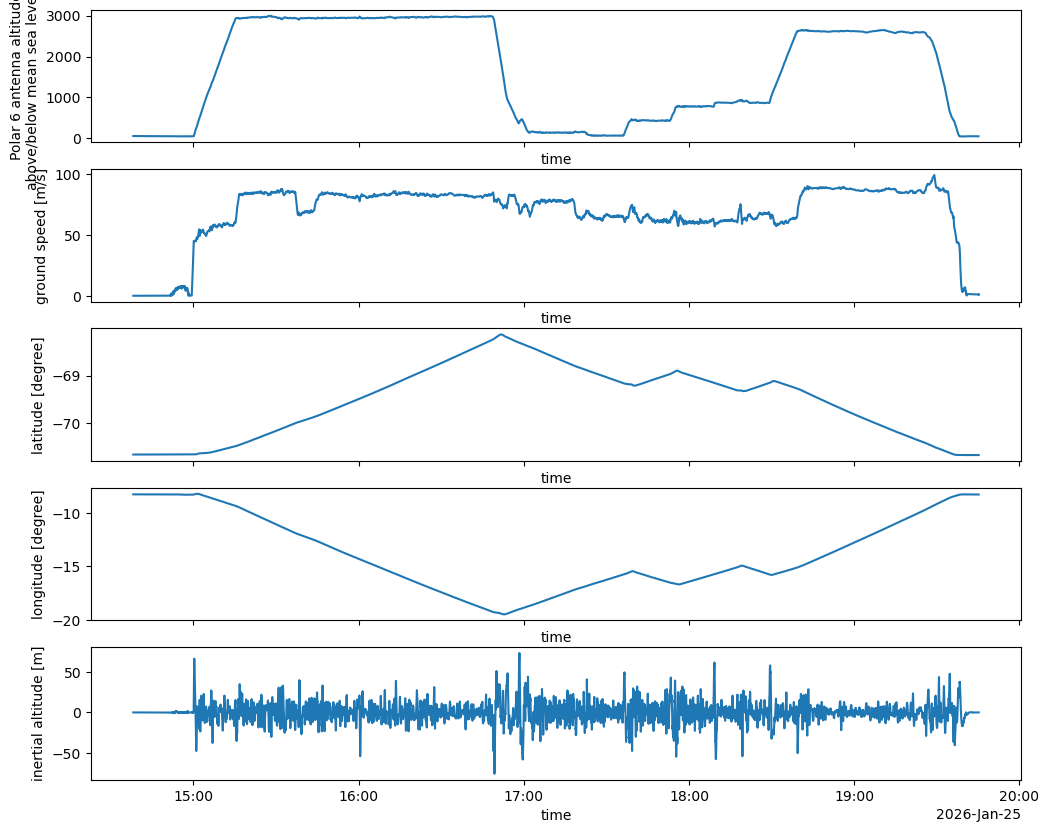

In [72]:
start = np.datetime64("2024-04-29T10:28:00")
stop = np.datetime64("2024-04-29T13:18:30")

# usefule variables: gs,h_ins, lat, lon, h_gpgga

#data.gs.plot()
fig, axs = plt.subplots(5,1,figsize=(12,10),sharex=True)

for v, ax in zip(["h_gpgga", "gs", "lat", "lon", "h"], fig.get_axes()):
    data[v].plot(ax = ax)
#    ax.axvline(start, c = "tab:red")
#    ax.axvline(stop, c = "tab:red")

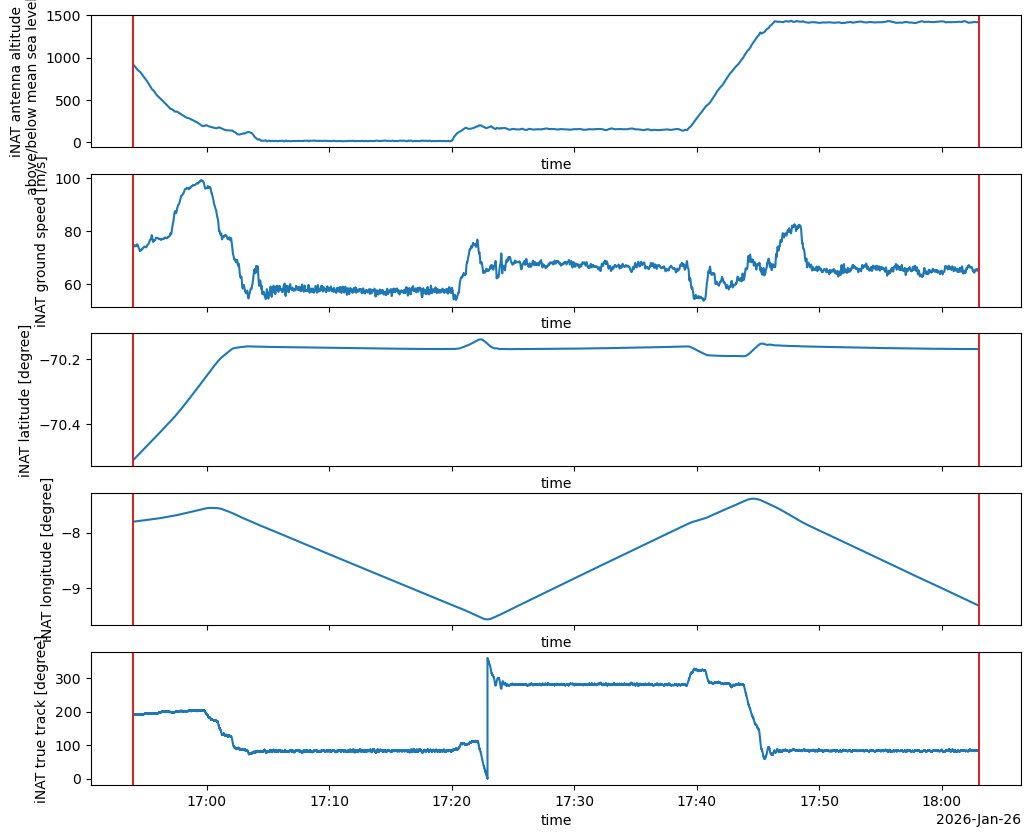

In [91]:
# For T-Bird

start = np.datetime64("2026-01-26T16:54:00")
stop = np.datetime64("2026-01-26T18:03:00")

# usefule variables: gs_inat, h_inat, lat_inat, lon_inat

#data.gs.plot()
fig, axs = plt.subplots(5,1,figsize=(12,10),sharex=True)

for v, ax in zip(["h_inat", "gs_inat", "lat_inat", "lon_inat", "ttrk_inat"], fig.get_axes()):
    data[v].sel(time = slice(start,stop)).plot(ax = ax)
#    data[v].plot(ax = ax)
    ax.axvline(start, c = "tab:red")
    ax.axvline(stop, c = "tab:red")

#fig.savefig("/Users/lakoeh001/Desktop/tbird_gps_20240410.pdf")

## Get segments

Each flight is divided into segments to make it easier to work with the data.

In [5]:
# Calculate parameters useful for segment determination

start = config["flights"][flight]["start"]
stop = config["flights"][flight]["stop"]

pf = "noseboom"
twist_angle = np.deg2rad(config["campaign"]["noseboom_twist"])

for v in ["qb", "qc", "ps", "alpha", "beta"]:
    da = corr.alignement_correction(data, fhp_params, v, pf, twist_angle).rename(v)
    try:
        data_corr[v] = da
    except:
        data_corr = da.to_dataset()

# Some corrections:
data_corr["qc"] = data_corr["qc"].where(data_corr["qc"]>0, other = 0)
data_corr["alpha"] = data_corr["alpha"].where(data_corr["qc"]>500, other = 0)
data_corr["beta"] = data_corr["beta"].where(data_corr["qc"]>500, other = 0)

# adiabatic corrections for sensors in Rosemount/Goodrich housings
etaE = 1.00025  # recovery factor for deiced sensors
for temp in ["TejB", "ThuB", "Te_N", "ThuN", "TejN"]:
    name = f"{temp}_corr"
    if temp == "TejB":
        da = corr.sat_correction(data, data_corr, temp, recovery=etaE).rename(name)
    else:
        da = corr.sat_correction(data, data_corr, temp).rename(name)
    try:
        data_corr[name] = da
    except:
        data_corr = da.to_dataset()

# Correct relative humidity using the Magnus formula for the saturation pressure.
rh_corr = corr.humidity_correction(data.rFHuN, data.ThuN, data_corr.Te_N_corr)
data_corr["rFHuN_corr"] = rh_corr

# Correction of INS with GPS
w_ins = corr.get_w_ins(data, start, stop)
h_ins = corr.get_h_ins(w_ins["w_ins"])
data = xr.merge([data, w_ins, h_ins])

for v in ["lat", "lon", "gs", "h_ins", "w_ins", "vew", "vns"]:
    gps_corr = corr.correct_ins_with_gps(data, v)
    data_corr = xr.merge([data_corr, gps_corr])

ttrk_corr = corr.correct_ttrk_ins_with_gps(data, data_corr, "ttrk")
data_corr = xr.merge([data_corr, ttrk_corr])

# Calculate true airspeed
data_corr["tas"] = corr.get_true_air_speed(data_corr, pf)

for v in ["u", "v", "vertwind"]:
    wind_comp = corr.get_wind_component(data, data_corr, v, pf)
    data_corr[v] = wind_comp

In [6]:
cal_segs = config["flights"][flight]["calibration"]

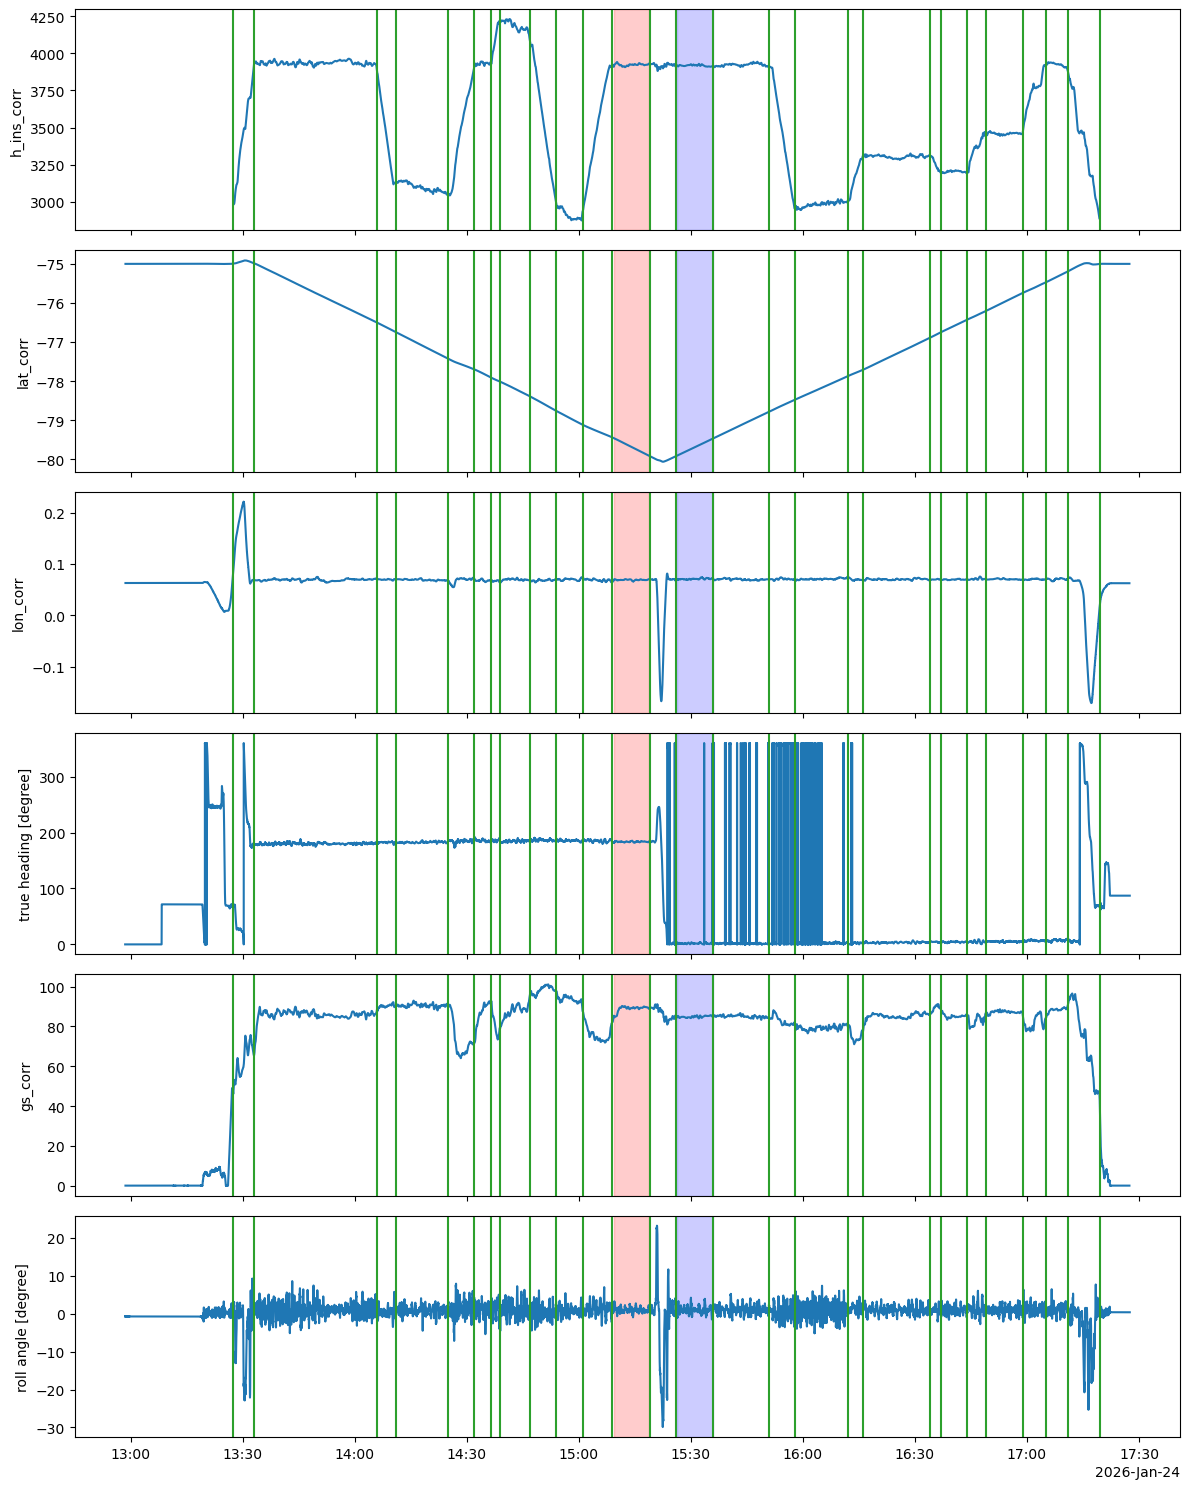

In [7]:
fig, axs = plt.subplots(6,1,figsize=(12,15),sharex=True)

data_corr.h_ins_corr.plot(ax = axs[0])
data_corr.lat_corr.plot(ax = axs[1])
data_corr.lon_corr.plot(ax = axs[2])
data.thdg.plot(ax = axs[3])
data_corr.gs_corr.plot(ax = axs[4])
data["roll"].plot(ax = axs[5])

seglist = []

#calsegs = ["2026-01-21T13:04:00", "2026-01-21T13:13:00",
#           "2026-01-21T13:19:00", "2026-01-21T13:26:00"]
calsegs = []

# If segments are aleady determined, it is possible to plot them here with the switch:
if 1:
    try:
        seg_fn = config["paths"]["segments"]
        segments = h.import_dictionary(seg_fn)
        flight_segments = segments["flights"][flight]["segments"]
        for i in np.arange(len(flight_segments)):
            t = flight_segments[i]['time']
            seglist.append(t)
    except:
        print("No segment file available")

seglist = np.array(seglist).astype("datetime64")
calsegs = np.array(calsegs).astype("datetime64")

for ax in fig.get_axes():
    ax.set_xlabel("")
    for s in seglist:
        ax.axvline(s, color = "tab:green")
    for cal in calsegs:
        ax.axvline(cal, color = "tab:red")

# If calibration segments are already available:
for ax in fig.get_axes():
    for key, val in cal_segs.items():
        start = val['start']
        stop = val['stop']
        
        # optional: different colors for "out" vs "ret"
        color = 'red' if 'out' in key else 'blue'
        
        ax.axvspan(start, stop, alpha=0.2, color=color)

plt.tight_layout()

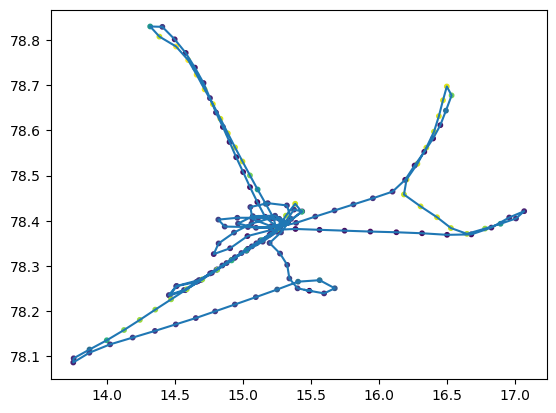

In [197]:
# The flight track might also be useful for the segemnts:
min = data_corr.resample(time = "1min").mean()

plt.plot(min.lon_corr, min.lat_corr)
plt.scatter(min.lon_corr, min.lat_corr, c=min.h_ins_corr.values, s=10, cmap="viridis")

#### Adjusting calibration segments:

Calibration segments are mainly identified looking at the segmentation above and from the flight reports where it is indicated when they were flown. However, they need to be adjusted to have the same length, i.e. same start and end point.

In [8]:
cal_segs

{'out1': {'start': datetime.datetime(2026, 1, 24, 15, 9, 30, 760000),
  'stop': datetime.datetime(2026, 1, 24, 15, 18, 49, 980000)},
 'ret1': {'start': datetime.datetime(2026, 1, 24, 15, 26, 13, 480000),
  'stop': datetime.datetime(2026, 1, 24, 15, 36)}}

In [9]:
calnum = 1
out = data_corr.sel(time = slice(cal_segs[f"out{calnum}"]["start"],cal_segs[f"out{calnum}"]["stop"]))
ret = data_corr.sel(time = slice(cal_segs[f"ret{calnum}"]["start"],cal_segs[f"ret{calnum}"]["stop"]))

In [16]:
import numpy as np
from scipy.spatial import cKDTree

def latlon_to_xyz(lat, lon, R=6371000.0):
    lat_r = np.radians(lat)
    lon_r = np.radians(lon)
    x = R * np.cos(lat_r) * np.cos(lon_r)
    y = R * np.cos(lat_r) * np.sin(lon_r)
    z = R * np.sin(lat_r)
    return np.column_stack([x, y, z])

xyz_out = latlon_to_xyz(out.lat_corr.values, out.lon_corr.values)
xyz_ret = latlon_to_xyz(ret.lat_corr.values, ret.lon_corr.values)

# 1. Bogenlänge entlang von "out" als gemeinsames Lineal
seg_len = np.linalg.norm(np.diff(xyz_out, axis=0), axis=1)
s_out = np.concatenate([[0], np.cumsum(seg_len)])  # Meter entlang des out-Tracks

# 2. ret-Punkte auf den out-Track projizieren (nearest neighbor)
tree_out = cKDTree(xyz_out)
dist_ret, idx_ret = tree_out.query(xyz_ret)   # idx_ret zeigt auf Position in out

threshold_m = 60
mask_ret = dist_ret < threshold_m

s_ret = s_out[idx_ret]   # ret-Punkte jetzt im selben "s"-Koordinatensystem wie out

# 3. Überlappungsbereich in s bestimmen (nur gültige, nahe Punkte berücksichtigen)
s_out_valid = s_out          # out hat s per Definition komplett
s_ret_valid = s_ret[mask_ret]

s_min = max(s_out_valid.min(), s_ret_valid.min())
s_max = min(s_out_valid.max(), s_ret_valid.max())

# 4. Zeiten rausholen: wo liegt jeder Track im überlappenden s-Bereich?
mask_out_overlap = (s_out >= s_min) & (s_out <= s_max)
mask_ret_overlap = mask_ret & (s_ret >= s_min) & (s_ret <= s_max)

start_out = out.time.values[mask_out_overlap][0]
stop_out  = out.time.values[mask_out_overlap][-1]

start_ret = ret.time.values[mask_ret_overlap][0]
stop_ret  = ret.time.values[mask_ret_overlap][-1]

print("out overlap:", start_out, "-", stop_out)
print("ret overlap:", start_ret, "-", stop_ret)

out overlap: 2026-01-29T12:13:20.170000000 - 2026-01-29T12:16:35.770000000
ret overlap: 2026-01-29T12:22:12.240000000 - 2026-01-29T12:26:00.000000000


The following is for checking the result:

In [10]:
print(f"out: alt = {out.h_ins_corr.mean().values:.3f}, tas = {out.tas.mean().values:.3f}, thdg = {out.ttrk_corr.mean().values:.2f}, lat = {out.lat_corr.values[0]:.3f}-{out.lat_corr.values[-1]:.3f}, lon = {out.lon_corr.values[0]:.3f}-{out.lon_corr.values[-1]:.3f}")
print(f"ret: alt = {ret.h_ins_corr.mean().values:.3f}, tas = {ret.tas.mean().values:.3f}, thdg + 180 = {((ret.ttrk_corr.mean().values + 180)%360):.2f}, lat = {ret.lat_corr.values[-1]:.3f}-{ret.lat_corr.values[0]:.3f}, lon = {ret.lon_corr.values[-1]:.3f}-{ret.lon_corr.values[0]:.3f}")

out: alt = 3923.141, tas = 85.030, thdg = 179.99, lat = -79.468--79.913, lon = 0.070-0.071
ret: alt = 3917.888, tas = 85.922, thdg + 180 = 18.79, lat = -79.468--79.913, lon = 0.070-0.069


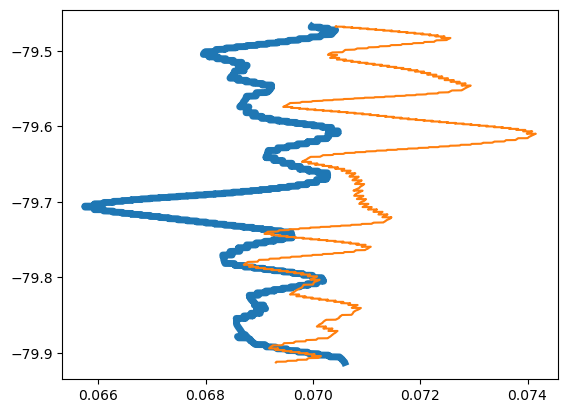

In [11]:
plt.plot(out.lon_corr, out.lat_corr, linewidth = 5)
plt.plot(ret.lon_corr, ret.lat_corr)

In [12]:
import numpy as np
import xarray as xr
from scipy.spatial import cKDTree

def latlon_to_xyz(lat, lon, R=6371000.0):
    lat_r = np.radians(lat)
    lon_r = np.radians(lon)
    x = R * np.cos(lat_r) * np.cos(lon_r)
    y = R * np.cos(lat_r) * np.sin(lon_r)
    z = R * np.sin(lat_r)
    return np.column_stack([x, y, z])

# xyz für beide Legs
xyz_out = latlon_to_xyz(out.lat_corr.values, out.lon_corr.values)
xyz_ret = latlon_to_xyz(ret.lat_corr.values, ret.lon_corr.values)

# KD-Tree über ret, out dagegen matchen
tree = cKDTree(xyz_ret)
dist, idx = tree.query(xyz_out)

threshold_m = 2000  # anpassen je nach GPS-Genauigkeit / Trackbreite
mask = dist < threshold_m

result = xr.Dataset({
    "time_out": ("match", out.time.values[mask]),
    "time_ret": ("match", ret.time.values[idx[mask]]),
    "distance_m": ("match", dist[mask]),
})

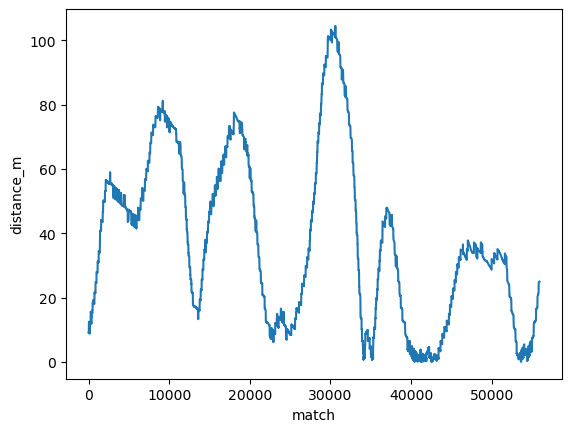

In [13]:
result.distance_m.plot()

### Segmentation documentation

For the GitHub Repos, I want to transform the segmentation list in an html table.

In [7]:
# This is for having a csv file with the times and the segment types and comments. There might be a more elegant way to do this, maybe adjust for the next campaign.

fn_in = "/Users/lakoeh001/AWINextcloud/personal/lakoeh001/campaigns/2024bacsam2/BACSAM2FlightSegmentTypes.csv"
df = pd.read_csv(fn_in, sep = ";")
byflight = df.groupby(by = "Flight")

In [8]:
flight_dict = {}
#flights = [11,12,21,22,31,32,33,4,5,6,7,8,9,10] # SANAT
flights = [1,2,3,40,41,42,5,6,7,8,9,10,11] # BACSAM II
for f in flights:
    selected_flight = byflight.get_group(f)
    flight_list = []
    for i in np.arange(len(selected_flight)):
        seg_info = selected_flight.iloc[i]
        if type(seg_info["Comment"]) == type("str"):
            comment = seg_info["Comment"]
        else:
            comment = ""
        segs = {"segment" : int(seg_info["Segment"]), "time": seg_info["Time"], "type": seg_info["Type"], "comment": comment}
        flight_list.append(segs)
    flight_dict[f] = {"segments": flight_list}

flight_segments = {"flights": flight_dict}

In [9]:
fn_out = "/Users/lakoeh001/AWI/Programmierung/bacsam2_processing/bacsam2_flight_segements.yaml" # BACSAM II
with open(fn_out, 'w') as file:
    yaml.safe_dump(flight_segments, file, sort_keys=False)

In [10]:
def generate_html_table(data, output_file):
    html = []

    html.append('<table style="font-size:90%; border-collapse:collapse;">')

    html.append("""
<thead>
<tr>
<th>Flight</th>
<th>Segment</th>
<th>Time</th>
<th>Type</th>
<th>Comment</th>
</tr>
</thead>
<tbody>
""")

    for flight_id, flight_data in data["flights"].items():

        segments = flight_data["segments"]
        rowspan = len(segments)

        for i, seg in enumerate(segments):

            html.append("<tr>")

            # Only write flight number once with rowspan
            if i == 0:
                html.append(f'<td rowspan="{rowspan}">{flight_id}</td>')

            html.append(f"<td>{seg['segment']}</td>")
            html.append(f"<td>{seg['time']}</td>")
            html.append(f"<td>{seg['type']}</td>")
            html.append(f"<td>{seg.get('comment', '')}</td>")

            html.append("</tr>")

    html.append("</tbody></table>")

    with open(output_file, "w") as f:
        f.write("\n".join(html))

    print(f"HTML table written to {output_file}")

In [11]:
# BACSAM II
fn_flightsegs = "/Users/lakoeh001/AWI/Programmierung/bacsam2_processing/bacsam2_flight_segements.yaml"
fn_html_out = "/Users/lakoeh001/AWI/Programmierung/bacsam2_processing/bacsam2_flight_segements.html"

with open(fn_flightsegs) as f:
    segments = yaml.safe_load(f)

generate_html_table(segments, fn_html_out)

HTML table written to /Users/lakoeh001/AWI/Programmierung/bacsam2_processing/bacsam2_flight_segements.html


## Check qb

For SANAT, qb, and thus beta has, a strong positive bias. We are not sure where this comes from. Something might have been tilted or something was wrong with the power box. Anyway, we are able to correct this with beta_0. Here, we are only doing some checks to understand what is going on. This also means, we cannot determine a tilt angle.

It's not a constant offset since 0 is met very well when the aircraft is on the ground. Thus, it has to be something during the flight. It might be that the aircraft wasn't packed symmetrically. The mean roll over the whole campaign is 0.5˚. For BACSAM II, it was -0.3˚. However, this should be correctable with a turn of qa and qb which doesn't work. So, it has to be something different.
* It's not height dependent
* It's probably not the aircraft. Otherwise, the effect should have the same size in qa and should be easily correctable by turning qa into qb a bit.
* It's not a global offset. When the aircraft is on the ground, qb = 0 as it should be.
* Could the powerbox or the ad wandler be broken? But wouldn't the data then look really wrong which it doesn't?
* The noseboom itself shouldn't be twisted.
* The sonde itself could be a bit twisted but this should be the same as for a tilted airplane.
* I don't have more ideas

Still, we think that the effect is corrected by the beta_0 determination.

Flight 11 (20260121):  m = -0.002532,  c = 0.112637,  -c/m = 44.482886
Flight 12 (20260121):  m = -0.002510,  c = 0.122711,  -c/m = 48.887922
Flight 21 (20260122):  m = -0.002091,  c = 0.145351,  -c/m = 69.512742
Flight 22 (20260122):  m = -0.001884,  c = 0.185958,  -c/m = 98.722935
Flight 31 (20260124):  m = -0.002125,  c = 0.165059,  -c/m = 77.665658
Flight 32 (20260124):  m = -0.001817,  c = 0.201492,  -c/m = 110.922283
Flight 33 (20260124):  m = -0.002368,  c = 0.209178,  -c/m = 88.351159
Flight 04 (20260125):  m = -0.002060,  c = 0.201314,  -c/m = 97.736180
Flight 05 (20260125):  m = -0.002274,  c = 0.190328,  -c/m = 83.715139
Flight 06 (20260126):  m = -0.003813,  c = 0.178642,  -c/m = 46.851070
Flight 07 (20260127):  m = -0.003027,  c = 0.175325,  -c/m = 57.912437
Flight 08 (20260127):  m = -0.002963,  c = 0.189570,  -c/m = 63.971979
Flight 09 (20260129):  m = -0.003211,  c = 0.199638,  -c/m = 62.173185
Flight 10 (20260129):  m = -0.001708,  c = 0.204654,  -c/m = 119.832212


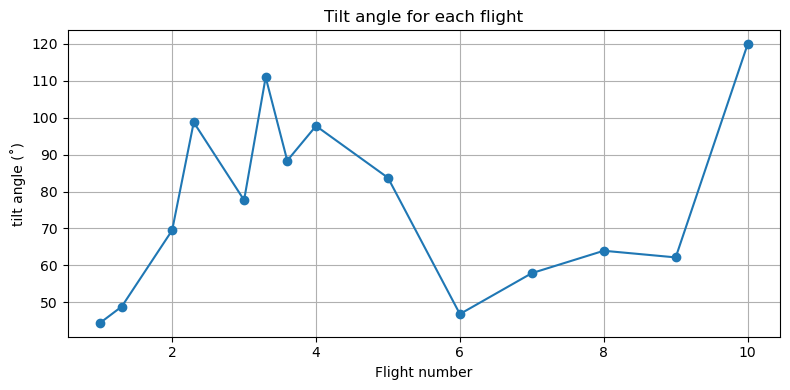

In [111]:
mus = xr.DataArray(
    np.linspace(-10, 10, 21),
    dims="mu"
)
date_dict = {11: "20260121", 12: "20260121", 21: "20260122", 22: "20260122", 31: "20260124", 32: "20260124", 33: "20260124", 4: "20260125", 5: "20260125", 6: "20260126", 7: "20260127", 8: "20260127", 9: "20260129", 10: "20260129"}
results = {}

for flight in [11, 12, 21, 22, 31, 32, 33, 4, 5, 6, 7, 8, 9, 10]:
    flight_date = date_dict[flight]
    fn = outdir_raw+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_calibrated_raw_data.nc"
    data = xr.open_dataset(fn)
    sel = data.where(data.qcN > 1700)

    result = (
        (np.cos(np.deg2rad(mus)) * data.qbN - np.sin(np.deg2rad(mus)) * sel.qaN) / sel.qcN
    ).mean(axis=1)

    beta_mean = xr.Dataset(
        coords={"mu": mus},
        data_vars={"beta_mean": (["mu"], result.values)}
    )

    m, c = np.polyfit(beta_mean.mu.values, beta_mean.beta_mean.values, 1)
    results[flight] = {"m": m, "c": c}
    print(f"Flight {flight:02} ({flight_date}):  m = {m:.6f},  c = {c:.6f},  -c/m = {-c/m:.6f}")

# Plot
flights = list(results.keys())
zero_crossings = [-results[f]["c"] / results[f]["m"] for f in flights]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot([1.0, 1.3, 2.0, 2.3, 3.0, 3.3, 3.6, 4, 5, 6, 7, 8, 9, 10], zero_crossings, marker="o", linestyle="-")
ax.set_xlabel("Flight number")
ax.set_ylabel("tilt angle (˚)")
ax.set_title("Tilt angle for each flight")
ax.grid(True)
plt.tight_layout()
plt.show()

In [123]:
sanat = xr.open_dataset("/Users/lakoeh001/AWI/Campaigns/20260103SANAT/Daten/Prozessierung/raw/SANAT_20260127_RF07_calibrated_raw_data.nc")
bacsam = xr.open_dataset("/Users/lakoeh001/AWI/Campaigns/20240403BACSAMII/Daten/Prozessierung/raw/BACSAM2_20240423_RF07_calibrated_raw_data.nc")

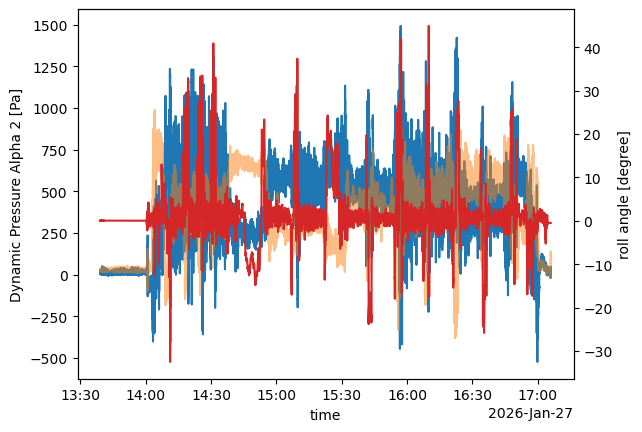

In [131]:
sanat = xr.open_dataset("/Users/lakoeh001/AWI/Campaigns/20260103SANAT/Daten/Prozessierung/raw/SANAT_20260127_RF08_calibrated_raw_data.nc")

fig, ax = plt.subplots(1,1,)

ax2 = ax.twinx()

(sanat.qbN).plot(ax = ax)
(sanat.qaN).plot(ax = ax, c = "tab:orange", alpha = 0.5)
#sanat.h_gpgga.plot(ax = ax2, c = "tab:red")
sanat["roll"].plot(ax = ax2, c = "tab:red")

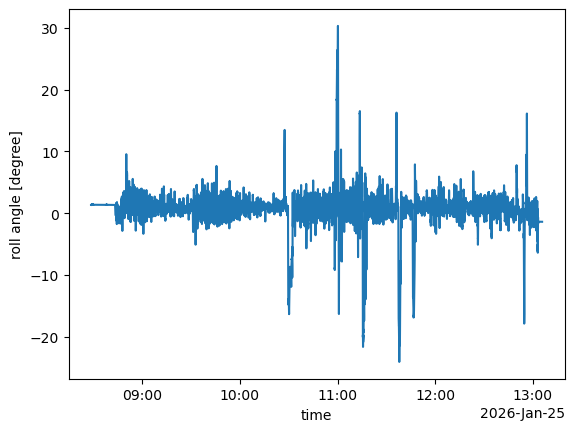

In [118]:
sanat["roll"].plot()

In [124]:
sanat["roll"].mean()

<xarray.DataArray 'roll' ()>
array(0.58541535)

In [139]:
roll_mean = 0
for flight in list(config["flights"].keys()):

    flight_date = str(config["flights"][flight]["date"]).replace("-","")
    fn_in = outdir_raw+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_calibrated_raw_data.nc"
    data = xr.open_dataset(fn_in)
    fn_out = outdir_nb+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_noseboom_100Hz.nc"
    data_proc = xr.open_dataset(fn_out)
    roll_mean = roll_mean + data_proc["roll"].mean()
    print(f"flight {flight}: {data_proc["roll"].mean().values}")

roll_mean = roll_mean/len(list(config["flights"].keys()))

flight 11: -0.4398446549074029
flight 12: 0.21253577842024235
flight 21: -0.2707856460815609
flight 22: 0.7766400875233591
flight 31: 0.02056581066989824
flight 32: 0.5935706655956204
flight 33: 0.736969320891987
flight 4: 0.6905720338381247
flight 5: 0.8361041780095978
flight 6: -0.26627742265304005
flight 7: 0.4099930408218899
flight 8: 1.6157313376411633
flight 9: 0.8423902283471936
flight 10: 1.1591028279726157


In [140]:
roll_mean

<xarray.DataArray 'roll' ()>
array(0.49409054)

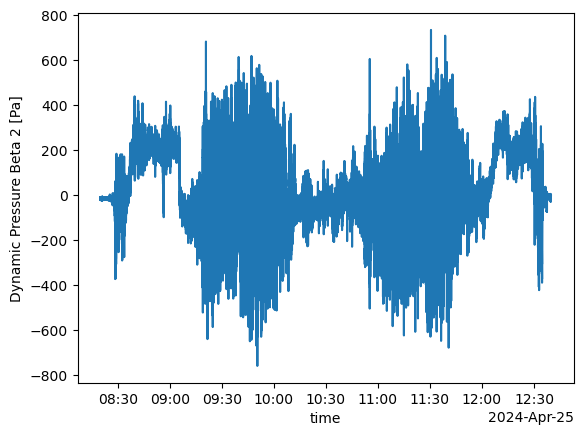

In [114]:
# For BACSAM II, qb is around 0.
bacsam.qbN.plot()

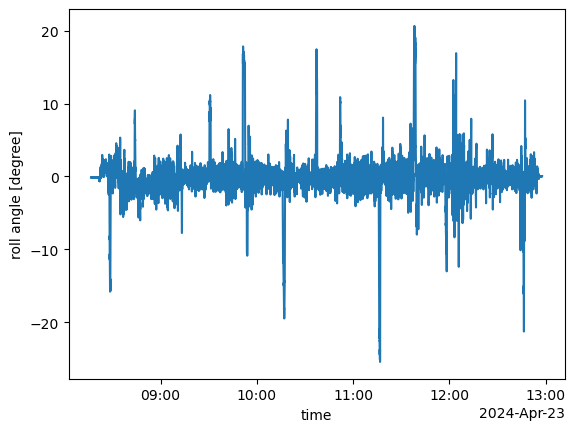

In [125]:
bacsam["roll"].plot()

In [126]:
bacsam["roll"].mean()

<xarray.DataArray 'roll' ()>
array(-0.16081616)

In [ ]:
roll_mean = 0
for flight in list(config["flights"].keys()):

    flight_date = str(config["flights"][flight]["date"]).replace("-","")
    fn_in = outdir_raw+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_calibrated_raw_data.nc"
    data = xr.open_dataset(fn_in)
    fn_out = outdir_nb+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_noseboom_100Hz.nc"
    data_proc = xr.open_dataset(fn_out)
    roll_mean = roll_mean + data_proc["roll"].mean()
    print(f"flight {flight}: {data_proc["roll"].mean().values}")

roll_mean = roll_mean/len(list(config["flights"].keys()))

Have a look at the raw data:

In [161]:
raw_bacsam = pd.read_csv("/Users/lakoeh001/AWI/Campaigns/20240403BACSAMII/Daten/Turbulenz/RF05_20240415/20240415_P6_05_Setra239R_7.DPB_raw.dat", header  = 4, sep = r'\s+', names = ["date", "time", "qbN_raw"])

<Axes: >

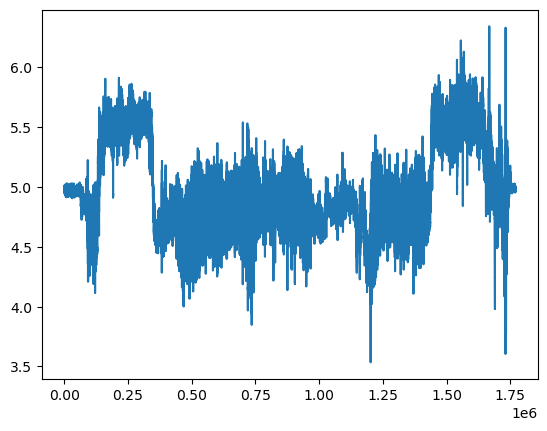

In [162]:
raw_bacsam.qbN_raw.plot()

In [163]:
raw_sanat = pd.read_csv("/Users/lakoeh001/AWI/Campaigns/20260103SANAT/Daten/RF09_20260129/20260129_RF09/20260129_P6_RF09_Setra239R_7.DPB_raw.dat", header  = 4, sep = r'\s+', names = ["date", "time", "qbN_raw"])

<Axes: >

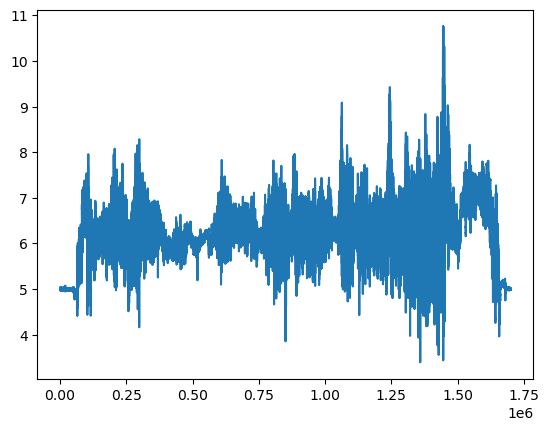

In [164]:
raw_sanat.qbN_raw.plot()

## Noseboom calibration

### dynamic pressure q

We do this according to the explanation in Hartmann 2018. One can either do the fit with or without offset.

In [9]:
def get_rho(ds, ds_proc):
    Rs = 287.0528
    rho = ds.psN / (Rs * ds_proc.t_air)
    return rho

In [10]:
outdir_raw = config["paths"]["outdirs"]["raw"]
outdir_nb = config["paths"]["outdirs"]["noseboom"]
campaign = config["campaign"]["name"]

We exclude the two calibration flight segments in flight 22 and 32 since here out and ret are two much off such that the calibration is not working anymore. To keep the information, here are the times used before:

22:
    calibration:
      out1:
        start: 2026-01-22T13:08:02.64
        stop: 2026-01-22T13:12:27.18
      ret1:
        start: 2026-01-22T13:24:09.24
        stop: 2026-01-22T13:29:00

32:
    calibration:
      out1:
        start: 2026-01-24T15:09:30.76
        stop: 2026-01-24T15:18:49.98
      ret1:
        start: 2026-01-24T15:26:13.48
        stop: 2026-01-24T15:36:00

In [28]:
qref = []
qi = np.array([])
gammaout = np.array([])
gammaret = np.array([])

for flight in list(config["flights"].keys()):

    flight_date = str(config["flights"][flight]["date"]).replace("-","")
    fn_in = outdir_raw+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_calibrated_raw_data.nc"
    data = xr.open_dataset(fn_in)
    fn_out = outdir_nb+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_noseboom_100Hz.nc"
    data_proc = xr.open_dataset(fn_out)
    try:
        cal_segments = config["flights"][flight]["calibration"]
        num = int(len(cal_segments)/2 + 1)
        for j in np.arange(1,num):
            out = data.sel(time = slice(cal_segments[f"out{j}"]["start"],cal_segments[f"out{j}"]["stop"]))
            ret = data.sel(time = slice(cal_segments[f"ret{j}"]["start"],cal_segments[f"ret{j}"]["stop"]))
            out_proc = data_proc.sel(time = slice(cal_segments[f"out{j}"]["start"],cal_segments[f"out{j}"]["stop"]))
            ret_proc = data_proc.sel(time = slice(cal_segments[f"ret{j}"]["start"],cal_segments[f"ret{j}"]["stop"]))

            out_proc["gs_corr"] = out_proc["gs"]
            ttrk_out = corr.correct_ttrk_ins_with_gps(out, out_proc,"ttrk")
            ret_proc["gs_corr"] = ret_proc["gs"]
            ttrk_ret = corr.correct_ttrk_ins_with_gps(ret, ret_proc,"ttrk")

            gamma_out = (np.deg2rad(out.thdg - ttrk_out.ttrk_corr)).mean()
            gammaout = np.append(gammaout, gamma_out.values)
            gamma_ret = (np.deg2rad(ret.thdg - ttrk_ret.ttrk_corr)).mean()
            gammaret = np.append(gammaret, gamma_ret.values)
            v_ref = 0.5 * (out_proc.gs.mean()/np.cos(gamma_out) + ret_proc.gs.mean()/np.cos(gamma_ret))
            rho = (get_rho(out, out_proc).mean() + get_rho(ret, ret_proc).mean())*0.5
            q_ref = 0.5 * rho * v_ref**2
            qref = np.append(qref, q_ref.values)
            q_i = (out.qcN.mean() + ret.qcN.mean())/2
            qi = np.append(qi, q_i.values)
    except:
        pass

In [29]:
# If fitted without offset as linear function, use this:
m = np.sum(qi * qref) / np.sum(qi * qi)
b = 0

In [30]:
m

1.10306983242156

In [35]:
1-m

-0.10306983242155998

In [31]:
b

0

In [32]:
fit = [b , b+ qi.max() * m ]

Text(0, 0.5, '$q_\\text{ref}$ (Pa)')

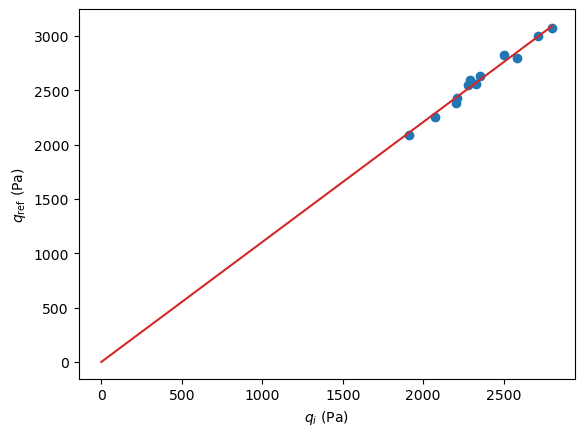

In [33]:
plt.scatter(qi, qref)
plt.plot([0, qi.max()], fit, c = "tab:red")
plt.xlabel(r"$q_i$ (Pa)")
plt.ylabel(r"$q_\text{ref}$ (Pa)")

#plt.savefig(f"{plot_dir}/q_fit.pdf")

Text(0, 0.5, '$\\gamma_\\text{ret}$ (˚)')

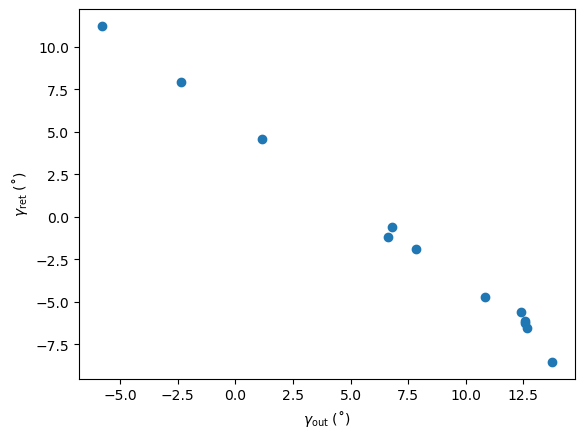

In [34]:
# This is a crosscheck if gamma_out and gamma_ret are consistent

plt.scatter(np.rad2deg(gammaout), np.rad2deg(gammaret))
#plt.plot([-12,6],[-12,6], c = "tab:red")
plt.xlabel(r"$\gamma_\text{out}$ (˚)")
plt.ylabel(r"$\gamma_\text{ret}$ (˚)")

### alpha

The alpha calibration is also explained in Hartmann et al 2028. We use version 2.

In [47]:
pf = "noseboom"

In [36]:
flights_with_calibration = [11, 4, 5, 7, 8, 9, 10] # SANAT

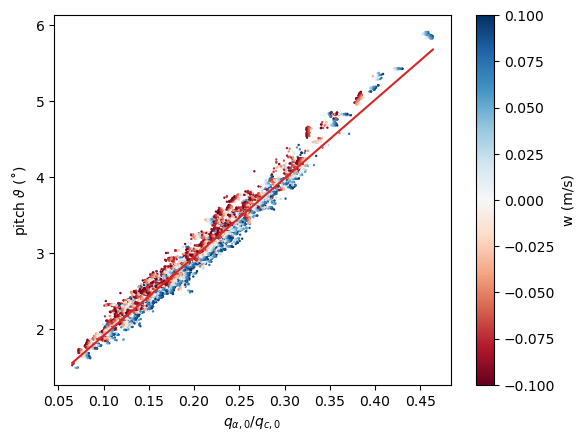

In [37]:
# Version 1: only calibration segments

pitch_all = np.array([])
qratio_all = np.array([])
wcut = 0.1
waircraft_cut = 0.05
roll_max = 2

for flight in flights_with_calibration:
    flight_date = str(config["flights"][flight]["date"]).replace("-","")
    fn_in = outdir_raw+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_calibrated_raw_data.nc"
    data = xr.open_dataset(fn_in)
    fn_out = outdir_nb+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_noseboom_100Hz.nc"
    data_proc = xr.open_dataset(fn_out)
    cal_segments = config["flights"][flight]["calibration"]
    num = int(len(cal_segments)/2 + 1)
    for j in np.arange(1,num):
        for dir in ["out", "ret"]:
            ds = data.sel(time = slice(np.datetime64(cal_segments[f"{dir}{j}"]["start"]),np.datetime64(cal_segments[f"{dir}{j}"]["stop"])))
            ds_proc = data_proc.sel(time = slice(cal_segments[f"{dir}{j}"]["start"],cal_segments[f"{dir}{j}"]["stop"]))
            sel = ds.where((np.abs(ds_proc.w) < wcut) & (np.abs(ds.w_bestvel) < waircraft_cut) & (np.abs(ds["roll"]) < roll_max), drop=True)
            sel_proc = ds_proc.where((np.abs(ds_proc.w) < wcut) & (np.abs(ds.w_bestvel) < waircraft_cut) & (np.abs(ds["roll"]) < roll_max), drop=True)
            pitch = sel.pit
            pitch_all = np.append(pitch_all, pitch.values)
            qratio = sel.qaN/sel.qcN
            qratio_all = np.append(qratio_all, qratio.values)
            plt.scatter(qratio,pitch, s = 0.5, c=sel_proc.w, vmin=-wcut, vmax=wcut, cmap="RdBu")

plt.xlabel(r"$q_{\alpha,0}/q_{c,0}$")
plt.ylabel(r"pitch $\vartheta$ (˚)")
plt.colorbar(label = "w (m/s)")
m, c = np.polyfit(qratio_all, pitch_all, 1)
fit = [qratio_all.min() * m + c, qratio_all.max() * m + c]
plt.plot([qratio_all.min(), qratio_all.max()], fit, c = "tab:red")

#plt.savefig(f"{plot_dir}/alpha_fit.pdf")

In [38]:
m

10.36294665893246

In [39]:
c

0.8718318277594016

In [56]:
calib_fn = f"{campaign_dir}/turbulence/fiveholeprobe_parameters_sanat.yaml"

def set_alpha_params(m, c):
    with open(calib_fn, "r") as f:
        calib = yaml.safe_load(f)
    calib[pf]["alpha"]["a0"] = float(c)
    calib[pf]["alpha"]["a1_qratio"] = float(m)
    with open(calib_fn, "w") as f:
        yaml.dump(calib, f)
        
def delete_output_files():
    patterns = [
        outdir_nb + f"/{campaign}_*_noseboom_100Hz.nc",
    ]
    for pattern in patterns:
        for fn in glob.glob(pattern):
            os.remove(fn)
#            print(f"Deleted: {fn}")

def run_polair(config_file):
    flights = "11 12 21 22 31 32 33 4 5 6 7 8 9 10"
    for flight in flights.split():
        subprocess.run(
            f"polair noseboom -f {flight} -c {config_file}",
            shell=True, check=True
        )

0th iteration
1th iteration
2th iteration
3th iteration
4th iteration
5th iteration
6th iteration
7th iteration
8th iteration
9th iteration
10th iteration
11th iteration
12th iteration
13th iteration
14th iteration
15th iteration
16th iteration
17th iteration
18th iteration
19th iteration
CPU times: user 2min 22s, sys: 1min 4s, total: 3min 26s
Wall time: 28min 52s


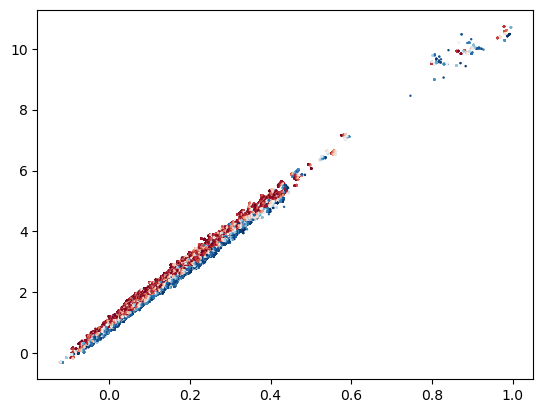

In [57]:
%%time
# Version 2: all flights. We assume that the restrictions of the roll, the vertical aircraft and wind speed already are sufficient to filter straigt flight segments.

iteration_num = 20

ms = [10.0]
cs = [1.0]
m = ms[0]
c = cs[0]
set_alpha_params(m, c)

all_flights = [11, 12, 21, 22, 31, 32, 33, 4, 5, 6, 7, 8, 9, 10] # SANAT

wcut = 0.1
waircraft_cut = 0.05
roll_max = 2

for i in np.arange(iteration_num):

    print(f"{i}th iteration")
    
    delete_output_files()
    run_polair(config_file)
    
    pitch_list = []
    qratio_list = []
    scatter_handles = []
    
    for flight in all_flights:
        start = config["flights"][flight]["start"]
        stop = config["flights"][flight]["stop"]
        flight_date = str(config["flights"][flight]["date"]).replace("-","")
        fn_in = outdir_raw+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_calibrated_raw_data.nc"
        fn_out = outdir_nb+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_noseboom_100Hz.nc"
    
        data = xr.open_dataset(fn_in)
        data_proc = xr.open_dataset(fn_out)
        # Align datasets to common time axis before masking
        data, data_proc = xr.align(data, data_proc, join="inner")
    
        w_ins = corr.get_w_ins(data, start, stop)
        ds = xr.merge([data, w_ins])
        w_p6 = corr.correct_ins_with_gps(ds, "w_ins")
    
        # Build mask once, apply without drop=True
        mask = (
            (np.abs(data_proc.w) < wcut) &
            (np.abs(w_p6.w_ins_corr) < waircraft_cut) &
            (np.abs(ds["roll"]) < roll_max)
        )
        mask_vals = mask.values
    
        pitch  = ds.pit.values[mask_vals]
        qratio = (ds.qaN / ds.qcN).values[mask_vals]
        w_proc = data_proc.w.values[mask_vals]
    
        pitch_list.append(pitch)
        qratio_list.append(qratio)
    
        sc = plt.scatter(qratio, pitch, s=0.5, c=w_proc, vmin=-wcut, vmax=wcut, cmap="RdBu")
        scatter_handles.append(sc)
    
    # Concatenate once at the end instead of appending in loop
    pitch_all  = np.concatenate(pitch_list)
    qratio_all = np.concatenate(qratio_list)
    
    mask_finite = np.isfinite(qratio_all) & np.isfinite(pitch_all)
    m, c = np.polyfit(qratio_all[mask_finite], pitch_all[mask_finite], 1)
    ms.append(m)
    cs.append(c)
    set_alpha_params(m, c)

CPU times: user 5.84 s, sys: 1.19 s, total: 7.03 s
Wall time: 7.08 s


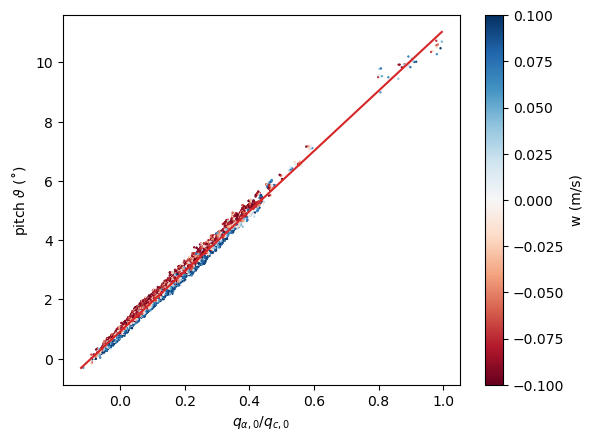

In [58]:
%%time

# Version 2: all flights. We assume that the restrictions of the roll, the vertical aircraft and wind speed already are sufficient to filter straigt flight segments.

all_flights = [11, 12, 21, 22, 31, 32, 33, 4, 5, 6, 7, 8, 9, 10] # SANAT

wcut = 0.1
waircraft_cut = 0.05
roll_max = 2

pitch_list = []
qratio_list = []
scatter_handles = []

for flight in all_flights:
    start = config["flights"][flight]["start"]
    stop = config["flights"][flight]["stop"]
    flight_date = str(config["flights"][flight]["date"]).replace("-","")
    fn_in = outdir_raw+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_calibrated_raw_data.nc"
    fn_out = outdir_nb+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_noseboom_100Hz.nc"

    data = xr.open_dataset(fn_in)
    data_proc = xr.open_dataset(fn_out)
    # Align datasets to common time axis before masking
    data, data_proc = xr.align(data, data_proc, join="inner")

    w_ins = corr.get_w_ins(data, start, stop)
    ds = xr.merge([data, w_ins])
    w_p6 = corr.correct_ins_with_gps(ds, "w_ins")

    # Build mask once, apply without drop=True
    mask = (
        (np.abs(data_proc.w) < wcut) &
        (np.abs(w_p6.w_ins_corr) < waircraft_cut) &
        (np.abs(ds["roll"]) < roll_max)
    )
    mask_vals = mask.values

    pitch  = ds.pit.values[mask_vals]
    qratio = (ds.qaN / ds.qcN).values[mask_vals]
    w_proc = data_proc.w.values[mask_vals]

    pitch_list.append(pitch)
    qratio_list.append(qratio)

    sc = plt.scatter(qratio, pitch, s=0.5, c=w_proc, vmin=-wcut, vmax=wcut, cmap="RdBu")
    scatter_handles.append(sc)

# Concatenate once at the end instead of appending in loop
pitch_all  = np.concatenate(pitch_list)
qratio_all = np.concatenate(qratio_list)

plt.xlabel(r"$q_{\alpha,0}/q_{c,0}$")
plt.ylabel(r"pitch $\vartheta$ (˚)")
plt.colorbar(scatter_handles[-1], label="w (m/s)")

mask_finite = np.isfinite(qratio_all) & np.isfinite(pitch_all)
m, c = np.polyfit(qratio_all[mask_finite], pitch_all[mask_finite], 1)
fit = [qratio_all.min() * m + c, qratio_all.max() * m + c]
plt.plot([qratio_all.min(), qratio_all.max()], fit, c="tab:red")

#plt.savefig(f"{plot_dir}/alpha_fit.png")

In [59]:
ms

[10.0,
 9.996625260488605,
 10.034185923511425,
 10.062028424769355,
 10.081673206518678,
 10.0972047470973,
 10.109506230341308,
 10.118946635720686,
 10.125939707632662,
 10.131140883244484,
 10.135292244177402,
 10.138177478944645,
 10.140405525339078,
 10.142245857466799,
 10.143694377952233,
 10.1446872600193,
 10.145408439535228,
 10.145957035852087,
 10.146580210355928,
 10.14696967424905,
 10.147213411776795]

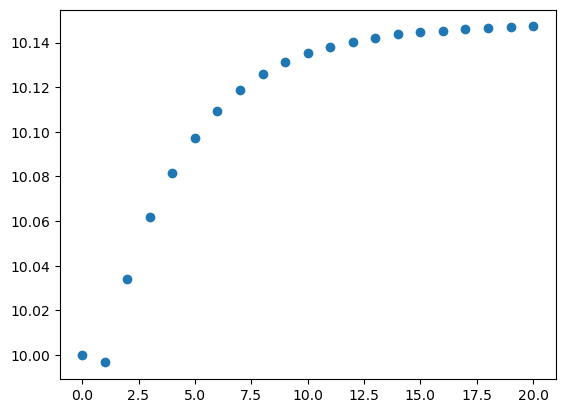

In [61]:
plt.scatter(np.arange(iteration_num +1), ms)

In [62]:
cs

[1.0,
 0.9475559939048935,
 0.9412247954198879,
 0.93691637516421,
 0.9338320037393212,
 0.931464107317299,
 0.9296193126989681,
 0.9281767259037569,
 0.9270898758157828,
 0.9263085685872368,
 0.9256650217609708,
 0.9252128837357766,
 0.9248740330861982,
 0.9245887546172765,
 0.9243668397760214,
 0.9242217420362708,
 0.9241089351866077,
 0.9240302185501592,
 0.9239466299574984,
 0.9238841120548591,
 0.9238444145280069]

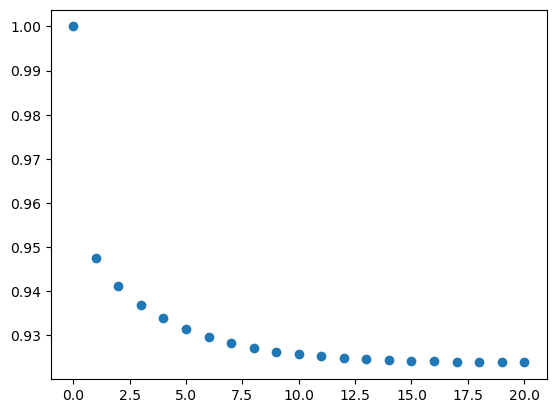

In [63]:
plt.scatter(np.arange(iteration_num+1), cs)

Nice, it converges for the noseboom.

CPU times: user 25 s, sys: 7.63 s, total: 32.6 s
Wall time: 7.52 s


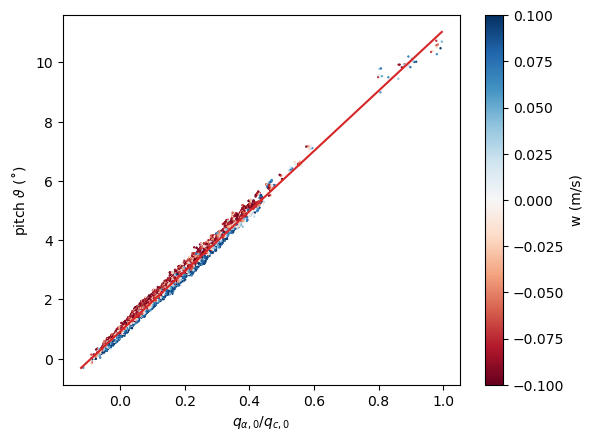

In [64]:
%%time

# Version 3: all flights seperately. This is a check if there is a drift and flights have to be handled sperately.

all_flights = [11, 12, 21, 22, 31, 32, 33, 4, 5, 6, 7, 8, 9, 10] # SANAT

wcut = 0.1
waircraft_cut = 0.05
roll_max = 2

pitch_list = []
qratio_list = []
scatter_handles = []
m_flights = []
c_flights = []

for flight in all_flights:
    start = config["flights"][flight]["start"]
    stop = config["flights"][flight]["stop"]
    flight_date = str(config["flights"][flight]["date"]).replace("-","")
    fn_in = outdir_raw+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_calibrated_raw_data.nc"
    fn_out = outdir_nb+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_noseboom_100Hz.nc"

    data = xr.open_dataset(fn_in)
    data_proc = xr.open_dataset(fn_out)
    # Align datasets to common time axis before masking
    data, data_proc = xr.align(data, data_proc, join="inner")

    w_ins = corr.get_w_ins(data, start, stop)
    ds = xr.merge([data, w_ins])
    w_p6 = corr.correct_ins_with_gps(ds, "w_ins")

    # Build mask once, apply without drop=True
    mask = (
        (np.abs(data_proc.w) < wcut) &
        (np.abs(w_p6.w_ins_corr) < waircraft_cut) &
        (np.abs(ds["roll"]) < roll_max)
    )
    mask_vals = mask.values

    pitch  = ds.pit.values[mask_vals]
    qratio = (ds.qaN / ds.qcN).values[mask_vals]
    w_proc = data_proc.w.values[mask_vals]

    # Per-flight fit
    mf = np.isfinite(qratio) & np.isfinite(pitch)
    m_f, c_f = np.polyfit(qratio[mf], pitch[mf], 1)
    m_flights.append(m_f)
    c_flights.append(c_f)

    pitch_list.append(pitch)
    qratio_list.append(qratio)

    sc = plt.scatter(qratio, pitch, s=0.5, c=w_proc, vmin=-wcut, vmax=wcut, cmap="RdBu")
    scatter_handles.append(sc)

# Concatenate once at the end instead of appending in loop
pitch_all  = np.concatenate(pitch_list)
qratio_all = np.concatenate(qratio_list)

plt.xlabel(r"$q_{\alpha,0}/q_{c,0}$")
plt.ylabel(r"pitch $\vartheta$ (˚)")
plt.colorbar(scatter_handles[-1], label="w (m/s)")

mask_finite = np.isfinite(qratio_all) & np.isfinite(pitch_all)
m, c = np.polyfit(qratio_all[mask_finite], pitch_all[mask_finite], 1)
fit = [qratio_all.min() * m + c, qratio_all.max() * m + c]
plt.plot([qratio_all.min(), qratio_all.max()], fit, c="tab:red")

In [65]:
np.mean(m_flights)

10.279823439539447

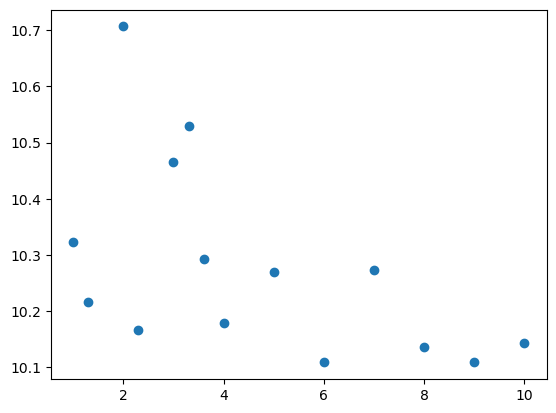

In [66]:
plt.scatter([1.0, 1.3, 2.0, 2.3, 3.0, 3.3, 3.6, 4, 5, 6, 7, 8, 9, 10],m_flights)

In [67]:
np.mean(c_flights)

0.9245850757777226

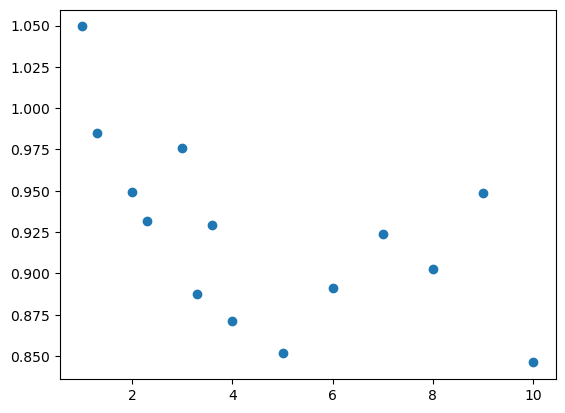

In [68]:
plt.scatter([1.0, 1.3, 2.0, 2.3, 3.0, 3.3, 3.6, 4, 5, 6, 7, 8, 9, 10],c_flights)

There is no drift in the noseboom, so it's okay to consider all flights together.

### beta_0

In [69]:
pf = "noseboom"

In [70]:
calib_fn = f"{campaign_dir}/turbulence/fiveholeprobe_parameters_sanat_2check.yaml"

def set_beta0(beta0):
    with open(calib_fn, "r") as f:
        calib = yaml.safe_load(f)
    calib[pf]["beta"]["a0"] = float(beta0)
    with open(calib_fn, "w") as f:
        yaml.dump(calib, f)

def delete_output_files():
    patterns = [
        outdir_nb + f"/{campaign}_*_noseboom_100Hz.nc",
    ]
    for pattern in patterns:
        for fn in glob.glob(pattern):
            os.remove(fn)
            print(f"Deleted: {fn}")

def run_polair(config_file):
    flights = "11 4 5 7 8 9 10"
    for flight in flights.split():
        subprocess.run(
            f"polair noseboom -f {flight} -c {config_file}",
            shell=True, check=True
        )

def compute_score():
    uperp_cals = []
    upara_cals = []
    
    for flight in [11, 4, 5, 7, 8, 9, 10]:
        flight_date = str(config["flights"][flight]["date"]).replace("-", "")
        fn_in  = outdir_raw + "/" + campaign + "_" + flight_date + f"_RF{flight:02}_calibrated_raw_data.nc"
        fn_out = outdir_nb + "/" + campaign + "_" + flight_date + f"_RF{flight:02}_noseboom_100Hz.nc"
        
        data      = xr.open_dataset(fn_in)
        data_proc = xr.open_dataset(fn_out)
        cal_segments = config["flights"][flight]["calibration"]
        num = int(len(cal_segments) / 2 + 1)
        
        for j in np.arange(1, num):
            uperp_sum = 0
            upara_sum = 0
            for dir in ["out", "ret"]:
                seg = cal_segments[f"{dir}{j}"]
                ds      = data.sel(time=slice(seg["start"], seg["stop"]))
                ds_proc = data_proc.sel(time=slice(seg["start"], seg["stop"]))
                thdg_rad = np.deg2rad(ds.thdg)
                uperp = ds_proc.u * np.cos(thdg_rad) - ds_proc.v * np.sin(thdg_rad)
                upara = ds_proc.u * np.sin(thdg_rad) + ds_proc.v * np.cos(thdg_rad)
                
                uperp_sum += uperp.mean().values
                upara_sum += upara.mean().values
            
            uperp_cals.append(uperp_sum)
            upara_cals.append(upara_sum)
    
    score_uperp = np.mean(np.abs(uperp_cals))
    score_upara = np.mean(np.abs(upara_cals))
    print(f"  mean|uperp| = {score_uperp:.4f},  mean|upara| = {score_upara:.4f}")
    return score_uperp, score_upara

In [78]:
# --- Main loop ---
beta0_values = np.linspace(0,10,11)
results = {}

for beta0 in beta0_values:
    print(f"\n--- beta0 = {beta0:.2f} ---")
    set_beta0(beta0)
    delete_output_files()
    run_polair(config_file)
    score_uperp, score_upara = compute_score()  # unpack tuple
    results[float(beta0)] = (score_uperp, score_upara)

best_beta0 = min(results, key=lambda b: results[b][0])
print(f"\nBest beta0: {best_beta0:.2f}  (uperp={results[best_beta0][0]:.4f}, upara={results[best_beta0][1]:.4f})")


--- beta0 = 0.00 ---
Deleted: /Users/lakoeh001/AWI/Campaigns/20260103SANAT/Daten/Prozessierung/noseboom/SANAT_20260125_RF04_noseboom_100Hz.nc
Deleted: /Users/lakoeh001/AWI/Campaigns/20260103SANAT/Daten/Prozessierung/noseboom/SANAT_20260125_RF05_noseboom_100Hz.nc
Deleted: /Users/lakoeh001/AWI/Campaigns/20260103SANAT/Daten/Prozessierung/noseboom/SANAT_20260127_RF07_noseboom_100Hz.nc
Deleted: /Users/lakoeh001/AWI/Campaigns/20260103SANAT/Daten/Prozessierung/noseboom/SANAT_20260121_RF11_noseboom_100Hz.nc
Deleted: /Users/lakoeh001/AWI/Campaigns/20260103SANAT/Daten/Prozessierung/noseboom/SANAT_20260129_RF09_noseboom_100Hz.nc
Deleted: /Users/lakoeh001/AWI/Campaigns/20260103SANAT/Daten/Prozessierung/noseboom/SANAT_20260127_RF08_noseboom_100Hz.nc
Deleted: /Users/lakoeh001/AWI/Campaigns/20260103SANAT/Daten/Prozessierung/noseboom/SANAT_20260129_RF10_noseboom_100Hz.nc
  mean|uperp| = 10.6945,  mean|upara| = 2.8702

--- beta0 = 1.00 ---
Deleted: /Users/lakoeh001/AWI/Campaigns/20260103SANAT/Daten/Pr

KeyboardInterrupt: 

In [ ]:
-4.73

In [74]:
set_beta0(best_beta0)

In [75]:
results

{-4.8: (2.0333453943971382, 2.7292285431553167),
 -4.79: (2.0288266888728543, 2.730518127054974),
 -4.779999999999999: (2.024307931764939, 2.731803556844852),
 -4.77: (2.019789123211042, 2.7330848324857975),
 -4.76: (2.0152702633488144, 2.7343619539387762),
 -4.75: (2.010751352315909, 2.735634921164887),
 -4.74: (2.0062323902499783, 2.7369037341253537),
 -4.7299999999999995: (2.0053896478844444, 2.738168392781524),
 -4.72: (2.005887442955752, 2.7394288970948755),
 -4.71: (2.0063852292852133, 2.7406852470270127),
 -4.699999999999999: (2.0068830068576653, 2.74193744253966),
 -4.6899999999999995: (2.007380775657945, 2.743185483594679),
 -4.68: (2.0078785356708884, 2.7444293701540476),
 -4.67: (2.0083762868813353, 2.7456691021798783),
 -4.66: (2.008874029274121, 2.746904679634405),
 -4.6499999999999995: (2.0093717628340833, 2.748136102479991),
 -4.64: (2.009869487546062, 2.749363370679122),
 -4.63: (2.0103672033948947, 2.7505864841944176),
 -4.619999999999999: (2.0112565251404306, 2.751805

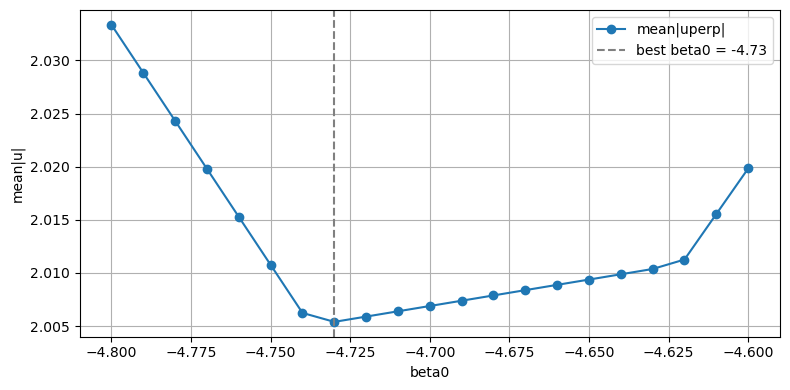

In [76]:
beta0s      = list(results.keys())
score_uperp = [results[b][0] for b in beta0s]
score_upara = [results[b][1] for b in beta0s]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(beta0s, score_uperp, marker="o", label="mean|uperp|")
#ax.plot(beta0s, score_upara, marker="o", label="mean|upara|")
ax.axvline(best_beta0, color="gray", linestyle="--", label=f"best beta0 = {best_beta0:.2f}")
ax.set_xlabel("beta0")
ax.set_ylabel("mean|u|")
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

#fig.savefig(f"{plot_dir}/beta0_determination.pdf")

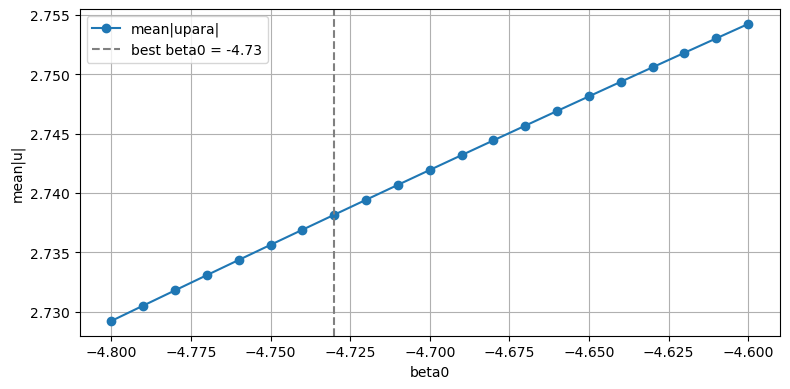

In [77]:
beta0s      = list(results.keys())
score_uperp = [results[b][0] for b in beta0s]
score_upara = [results[b][1] for b in beta0s]

fig, ax = plt.subplots(figsize=(8, 4))
#ax.plot(beta0s, score_uperp, marker="o", label="mean|uperp|")
ax.plot(beta0s, score_upara, marker="o", label="mean|upara|")
ax.axvline(best_beta0, color="gray", linestyle="--", label=f"best beta0 = {best_beta0:.2f}")
ax.set_xlabel("beta0")
ax.set_ylabel("mean|u|")
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

## T-Bird calibration

### dynamic pressure T-Bird

In [256]:
flights_with_calibration = [11, 4]
flights_with_tbird = [11, 12, 4, 5, 6]

In [257]:
def get_rho(ds, ds_proc):
    Rs = 287.0528
    rho = ds.psT / (Rs * ds_proc.t_air)
    return rho

In [258]:
outdir_raw = config["paths"]["outdirs"]["raw"]
outdir_tb = config["paths"]["outdirs"]["tbird"]
campaign = config["campaign"]["name"]

In [259]:
qref = []
qi = np.array([])
gammaout = np.array([])
gammaret = np.array([])

for flight in flights_with_calibration:
    flight_date = str(config["flights"][flight]["date"]).replace("-","")
    fn_in = outdir_raw+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_calibrated_raw_data.nc"
    data = xr.open_dataset(fn_in)
    fn_out = outdir_tb+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_tbird_100Hz.nc"
    data_proc = xr.open_dataset(fn_out)
    try:
        cal_segments = config["flights"][flight]["calibration"]
        num = int(len(cal_segments)/2 + 1)
        if flight == 8:                                                                             # BACSAM 2
            calibs = np.arange(2,num)
        else:
            calibs = np.arange(1,num)
        for j in calibs:
            out = data.sel(time = slice(cal_segments[f"out{j}"]["start"],cal_segments[f"out{j}"]["stop"]))
            ret = data.sel(time = slice(cal_segments[f"ret{j}"]["start"],cal_segments[f"ret{j}"]["stop"]))
            out_proc = data_proc.sel(time = slice(cal_segments[f"out{j}"]["start"],cal_segments[f"out{j}"]["stop"]))
            ret_proc = data_proc.sel(time = slice(cal_segments[f"ret{j}"]["start"],cal_segments[f"ret{j}"]["stop"]))

            out_proc["ttrk_inat_corr"] = out.ttrk_inat
            ttrk_out = corr.correct_ttrk_inat_with_gps(out, out_proc)
            ret_proc["ttrk_inat_corr"] = ret.ttrk_inat
            ttrk_ret = corr.correct_ttrk_inat_with_gps(ret, ret_proc)
            
            gamma_out = (np.deg2rad(out.thdg_inat - ttrk_out.ttrk_inat_corr)).mean()
            gammaout = np.append(gammaout, gamma_out.values)
            gamma_ret = (np.deg2rad(ret.thdg_inat - ttrk_ret.ttrk_inat_corr)).mean()
            gammaret = np.append(gammaret, gamma_ret.values)
            v_ref = 0.5 * (out_proc.gs.mean()/np.cos(gamma_out) + ret_proc.gs.mean()/np.cos(gamma_ret))
            rho = (get_rho(out, out_proc).mean() + get_rho(ret, ret_proc).mean())*0.5
            q_ref = 0.5 * rho * v_ref**2
            qref = np.append(qref, q_ref.values)
            q_i = (out.qcT.mean() + ret.qcT.mean())/2
            qi = np.append(qi, q_i.values)
    except:
        pass

In [260]:
# If fitted without offset as linear function, use this:
m = np.sum(qi * qref) / np.sum(qi * qi)
b = 0

In [261]:
m

1.1678001502990443

In [262]:
1-m

-0.16780015029904427

In [263]:
b

0

In [264]:
# Fehlerabschätzung
x = qi
y = qref

n = len(x)

m = np.sum(x*y) / np.sum(x**2)

res = y - m*x
s2 = np.sum(res**2) / (n - 1)

sigma_m = np.sqrt(s2 / np.sum(x**2))

In [265]:
sigma_m

0.004532387593801903

In [266]:
fit = [b , b+ qi.max() * m ]

Text(0, 0.5, '$q_\\text{ref}$ (Pa)')

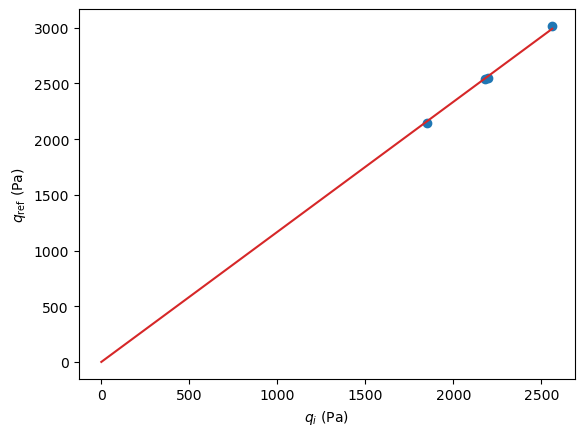

In [267]:
plt.scatter(qi, qref)
plt.plot([0, qi.max()], fit, c = "tab:red")
plt.xlabel(r"$q_i$ (Pa)")
plt.ylabel(r"$q_\text{ref}$ (Pa)")

#plt.savefig(f"{plot_dir/q_fit_tbird.pdf")

### alpha T-Bird

In [206]:
flights_with_calibration = [11, 4]

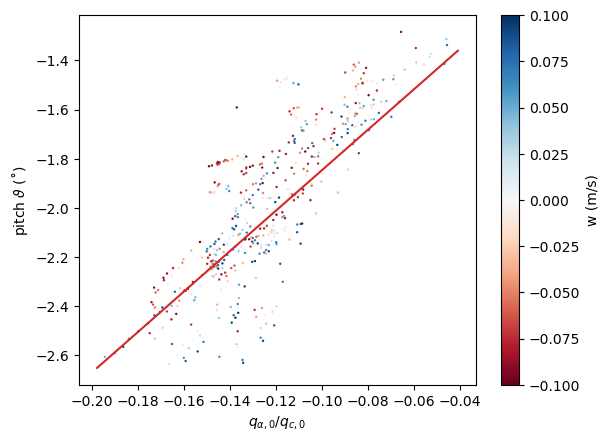

In [207]:
# Only calibration segments (this is not used)
pitch_all = np.array([])
qratio_all = np.array([])
wcut = 0.1
waircraft_cut = 0.05
roll_max = 5

for flight in flights_with_calibration:
    flight_date = str(config["flights"][flight]["date"]).replace("-","")
    fn_in = outdir_raw+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_calibrated_raw_data.nc"
    data = xr.open_dataset(fn_in)
    ds = data
    fn_out = outdir_tb+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_tbird_100Hz.nc"
    data_proc = xr.open_dataset(fn_out)
    ds_proc = data_proc
    cal_segments = config["flights"][flight]["calibration"]
    num = int(len(cal_segments)/2 + 1)
    if flight == 8:                                                                             # BACSAM 2
        calibs = np.arange(2,num)
    else:
        calibs = np.arange(1,num)
    for j in calibs:
        for dir in ["out", "ret"]:
            ds = data.sel(time = slice(np.datetime64(cal_segments[f"{dir}{j}"]["start"]),np.datetime64(cal_segments[f"{dir}{j}"]["stop"])))
            ds_proc = data_proc.sel(time = slice(cal_segments[f"{dir}{j}"]["start"],cal_segments[f"{dir}{j}"]["stop"]))
            sel = ds.where((np.abs(ds_proc.w) < wcut) & (np.abs(ds.w_bestvel) < waircraft_cut) & (np.abs(ds["roll"]) < roll_max), drop=True)
            sel_proc = ds_proc.where((np.abs(ds_proc.w) < wcut) & (np.abs(ds.w_bestvel) < waircraft_cut) & (np.abs(ds["roll"]) < roll_max), drop=True)
            pitch = -sel.pitch_inat
            pitch_all = np.append(pitch_all, pitch.values)
            qratio = sel.qaT/sel.qcT
            qratio_all = np.append(qratio_all, qratio.values)
    plt.scatter(qratio,pitch, s = 0.5, c=sel_proc.w, vmin=-wcut, vmax=wcut, cmap="RdBu")

plt.xlabel(r"$q_{\alpha,0}/q_{c,0}$")
plt.ylabel(r"pitch $\vartheta$ (˚)")
plt.colorbar(label = "w (m/s)")
m, c = np.polyfit(qratio_all, pitch_all, 1)
fit = [qratio_all.min() * m + c, qratio_all.max() * m + c]
plt.plot([qratio_all.min(), qratio_all.max()], fit, c = "tab:red")

#plt.savefig(f"{plot_dir/alpha_fit_tbird.pdf")

In [208]:
m

8.22429705481965

In [209]:
c

-1.0246808471622255

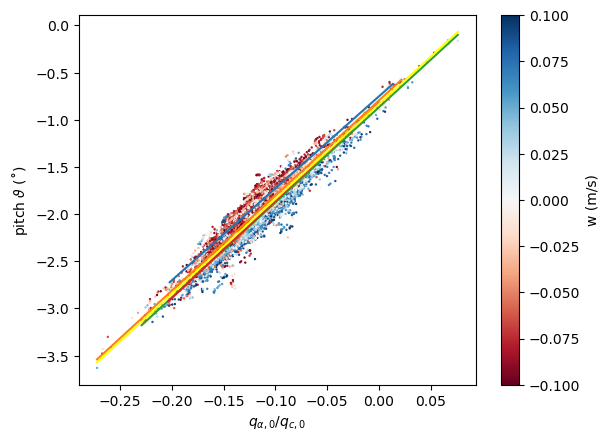

In [268]:
flights_with_tbird = [11, 4, 5, 6]
wcut = 0.1
waircraft_cut = 0.05
roll_max = 2
pitch_list = []
qratio_list = []
scatter_handles = []
m_flights = []
c_flights = []

# I only take straight segments
segments_dict = {
    11: [1, 3, 5, 7, 9, 11, 13, 15],
    12:  [1],
    4:  [1, 4, 6, 8, 10, 12, 14],
    5:  [1, 3, 5, 7, 9, 11, 13, 15],
    6:  [2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22],
}

for flight in flights_with_tbird:
    flight_date = str(config["flights"][flight]["date"]).replace("-", "")
    fn_in  = outdir_raw+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_calibrated_raw_data.nc"
    fn_out = outdir_tb +"/"+campaign+"_"+flight_date+f"_RF{flight:02}_tbird_100Hz.nc"
    data      = xr.open_dataset(fn_in).load()
    data_proc = xr.open_dataset(fn_out).load()

    # Select segments
    seg_mask = np.isin(data_proc.segment.values, segments_dict[flight])
    data_proc = data_proc.isel(time=seg_mask)

    # Match data to data_proc time axis — fast nearest-neighbor lookup
    data = data.sel(time=data_proc.time, method="nearest")

    # Compute w_inat in numpy directly
    h = data.h_inat.values
    w_inat = np.empty_like(h)
    w_inat[:-1] = np.diff(h) / 0.01
    w_inat[-1]  = np.nan

    # Build mask in numpy
    mask_vals = (
        (np.abs(data_proc.w.values) < wcut) &
        (np.abs(w_inat) < waircraft_cut) &
        (np.abs(data.roll_inat.values) < roll_max)
    )

    pitch  = -data.pitch_inat.values[mask_vals]
    qratio = (data.qaT.values / data.qcT.values)[mask_vals]
    w_proc = data_proc.w.values[mask_vals]

    pitch_list.append(pitch)
    qratio_list.append(qratio)

    # Per-flight fit
    mf = np.isfinite(qratio) & np.isfinite(pitch)
    m_f, c_f = np.polyfit(qratio[mf], pitch[mf], 1)
    m_flights.append(m_f)
    c_flights.append(c_f)

    sc = plt.scatter(qratio, pitch, s=0.5, c=w_proc, vmin=-wcut, vmax=wcut, cmap="RdBu")
    scatter_handles.append(sc)
    fit = [qratio.min() * m_f + c_f, qratio.max() * m_f + c_f]
    plt.plot([qratio.min(), qratio.max()], fit)

# Concatenate and overall fit
pitch_all  = np.concatenate(pitch_list)
qratio_all = np.concatenate(qratio_list)

mask_finite = np.isfinite(qratio_all) & np.isfinite(pitch_all)
m, c = np.polyfit(qratio_all[mask_finite], pitch_all[mask_finite], 1)
fit = [qratio_all.min() * m + c, qratio_all.max() * m + c]

plt.xlabel(r"$q_{\alpha,0}/q_{c,0}$")
plt.ylabel(r"pitch $\vartheta$ (˚)")
plt.colorbar(scatter_handles[-1], label="w (m/s)")
plt.plot([qratio_all.min(), qratio_all.max()], fit, c="yellow")

#plt.savefig(f"{plot_dir/alpha_fit_tbird.png")

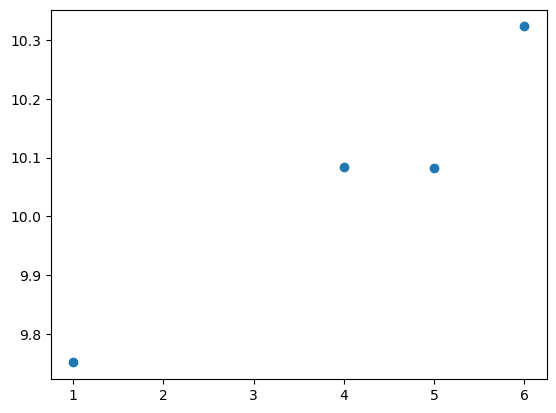

In [269]:
# How is the scattering for the different flights? m seems to be pretty consistent

plt.scatter([1, 4, 5, 6],m_flights)

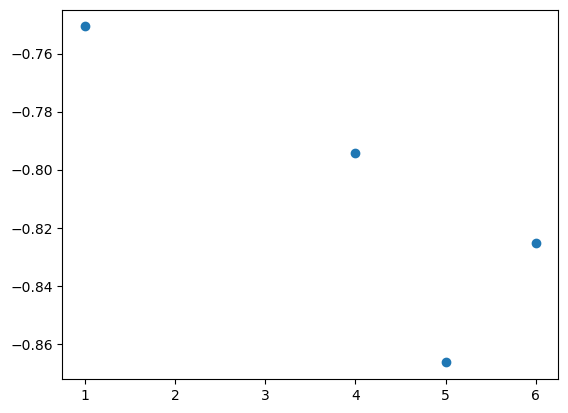

In [270]:
# But the offset is doing quite some jumps

plt.scatter([1, 4, 5, 6],c_flights)

For SANAT, this converges:

In [272]:
calib_fn = f"{campaign_dir}/turbulence/fiveholeprobe_parameters_sanat.yaml"

pf = "tbird"

def set_alpha_params(m, c):
    with open(calib_fn, "r") as f:
        calib = yaml.safe_load(f)
    calib[pf]["alpha"]["a0"] = float(c)
    calib[pf]["alpha"]["a1_qratio"] = float(m)
    with open(calib_fn, "w") as f:
        yaml.dump(calib, f)
        
def delete_output_files():
    patterns = [
        outdir_tb + f"/{campaign}_*_tbird_100Hz.nc",
    ]
    for pattern in patterns:
        for fn in glob.glob(pattern):
            os.remove(fn)
#            print(f"Deleted: {fn}")

def run_polair(config_file):
    flights = "11 4 5 6"
    for flight in flights.split():
        subprocess.run(
            f"polair tbird -f {flight} -c {config_file}",
            shell=True, check=True
        )

In [273]:
%%time
# Version 2: all flights. We assume that the restrictions of the roll, the vertical aircraft and wind speed already are sufficient to filter straigt flight segments.

iteration_num = 10

ms = [10.0]
cs = [-1.0]
m = ms[0]
c = cs[0]
set_alpha_params(m, c)

flights_with_tbird = [11, 4, 5, 6]

wcut = 0.1
waircraft_cut = 0.05
roll_max = 2

# I only take straight segments
segments_dict = {
    11: [1, 3, 5, 7, 9, 11, 13, 15],
    12:  [1],
    4:  [1, 4, 6, 8, 10, 12, 14],
    5:  [1, 3, 5, 7, 9, 11, 13, 15],
    6:  [2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22],
}

for i in np.arange(iteration_num):

    print(f"{i}th iteration")
    
    delete_output_files()
    run_polair(config_file)
    
    pitch_list = []
    qratio_list = []
    scatter_handles = []
    m_flights = []
    c_flights = []

    for flight in flights_with_tbird:
        flight_date = str(config["flights"][flight]["date"]).replace("-", "")
        fn_in  = outdir_raw+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_calibrated_raw_data.nc"
        fn_out = outdir_tb +"/"+campaign+"_"+flight_date+f"_RF{flight:02}_tbird_100Hz.nc"
        data      = xr.open_dataset(fn_in).load()
        data_proc = xr.open_dataset(fn_out).load()
    
        # Select segments
        seg_mask = np.isin(data_proc.segment.values, segments_dict[flight])
        data_proc = data_proc.isel(time=seg_mask)
    
        # Match data to data_proc time axis — fast nearest-neighbor lookup
        data = data.sel(time=data_proc.time, method="nearest")
    
        # Compute w_inat in numpy directly
        h = data.h_inat.values
        w_inat = np.empty_like(h)
        w_inat[:-1] = np.diff(h) / 0.01
        w_inat[-1]  = np.nan
    
        # Build mask in numpy
        mask_vals = (
            (np.abs(data_proc.w.values) < wcut) &
            (np.abs(w_inat) < waircraft_cut) &
            (np.abs(data.roll_inat.values) < roll_max)
        )
    
        pitch  = -data.pitch_inat.values[mask_vals]
        qratio = (data.qaT.values / data.qcT.values)[mask_vals]
        w_proc = data_proc.w.values[mask_vals]
    
        pitch_list.append(pitch)
        qratio_list.append(qratio)
    
        # Per-flight fit
        mf = np.isfinite(qratio) & np.isfinite(pitch)
        m_f, c_f = np.polyfit(qratio[mf], pitch[mf], 1)
        m_flights.append(m_f)
        c_flights.append(c_f)
    
    # Concatenate and overall fit
    pitch_all  = np.concatenate(pitch_list)
    qratio_all = np.concatenate(qratio_list)
    
    m = np.mean(m_f)
    ms.append(m)
    c = np.mean(c_f)
    cs.append(c)
    set_alpha_params(m, c)

0th iteration
1th iteration
2th iteration
3th iteration
4th iteration
5th iteration
6th iteration
7th iteration
8th iteration
9th iteration
CPU times: user 43.7 s, sys: 26.1 s, total: 1min 9s
Wall time: 5min


In [274]:
ms

[10.0,
 10.193847148947471,
 10.292685445756607,
 10.341914661685554,
 10.361695400129767,
 10.38289481564935,
 10.399505503422091,
 10.404918784837742,
 10.41032618293987,
 10.411880093420924,
 10.413283252783119]

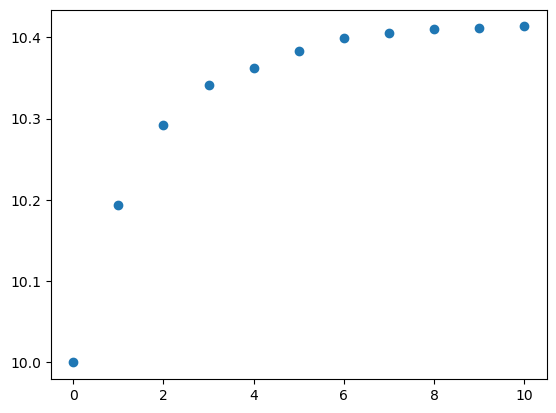

In [275]:
plt.scatter(np.arange(iteration_num +1), ms)

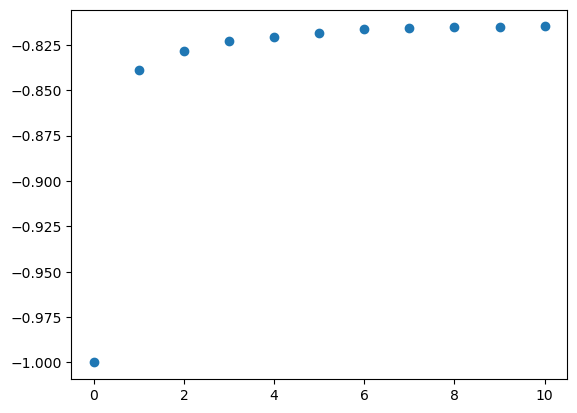

In [276]:
plt.scatter(np.arange(iteration_num +1), cs)

### beta_0 T-Bird

In [286]:
pf = "tbird"

calib_fn = f"{campaign_dir}/turbulence/fiveholeprobe_parameters_sanat.yaml"

def set_beta0(beta0):
    with open(calib_fn, "r") as f:
        calib = yaml.safe_load(f)
    calib[pf]["beta"]["a0"] = float(beta0)
    with open(calib_fn, "w") as f:
        yaml.dump(calib, f)

def delete_output_files():
    patterns = [
        outdir_tb + f"/{campaign}_*_tbird_100Hz.nc",
    ]
    for pattern in patterns:
        for fn in glob.glob(pattern):
            os.remove(fn)
            print(f"Deleted: {fn}")

def run_polair(config_file):
    flights = [11, 4]
    for flight in flights:
        subprocess.run(
            f"polair tbird -f {flight} -c {config_file}",
            shell=True, check=True
        )

def compute_score():
    uperp_cals = []
    upara_cals = []
    
    for flight in [11, 4]:
        flight_date = str(config["flights"][flight]["date"]).replace("-", "")
        fn_in  = outdir_raw + "/" + campaign + "_" + flight_date + f"_RF{flight:02}_calibrated_raw_data.nc"
        fn_out = outdir_tb + "/" + campaign + "_" + flight_date + f"_RF{flight:02}_tbird_100Hz.nc"
        
        data      = xr.open_dataset(fn_in)
        data_proc = xr.open_dataset(fn_out)
        cal_segments = config["flights"][flight]["calibration"]
        num = int(len(cal_segments) / 2 + 1)
        if flight == 8:                                                                             # BACSAM 2
            calibs = np.arange(2,num)
        else:
            calibs = np.arange(1,num)
        for j in calibs:
            uperp_sum = 0
            upara_sum = 0
            for dir in ["out", "ret"]:
                seg = cal_segments[f"{dir}{j}"]
                ds      = data.sel(time=slice(seg["start"], seg["stop"]))
                ds_proc = data_proc.sel(time=slice(seg["start"], seg["stop"]))

                # Get corrected true track:
#                da = corr.reverse_antennas(ds, "ttrk_inat", True).rename("ttrk_inat_corr")
#                data_corr = da.to_dataset()
#                thdg = (ds.thdg_inat + 180)#corr.correct_ttrk_inat_with_gps(ds, data_corr)
                thdg_rad = np.deg2rad(ds.thdg_inat + 180)#ttrk_corr.ttrk_inat_corr)
                uperp = ds_proc.u * np.cos(thdg_rad) - ds_proc.v * np.sin(thdg_rad)
                upara = ds_proc.u * np.sin(thdg_rad) + ds_proc.v * np.cos(thdg_rad)
                
                uperp_sum += uperp.mean().values
                upara_sum += upara.mean().values
            
            uperp_cals.append(uperp_sum)
            upara_cals.append(upara_sum)
    
    score_uperp = np.mean(np.abs(uperp_cals))
    score_upara = np.mean(np.abs(upara_cals))
    print(f"  mean|uperp| = {score_uperp:.4f},  mean|upara| = {score_upara:.4f}")
    return score_uperp, score_upara

In [287]:
# --- Main loop ---
beta0_values = np.linspace(0,2,21)
results = {}

for beta0 in beta0_values:
    print(f"\n--- beta0 = {beta0:.3f} ---")
    set_beta0(beta0)
    delete_output_files()
    run_polair(config_file)
    score_uperp, score_upara = compute_score()  # unpack tuple
    results[float(beta0)] = (score_uperp, score_upara)

best_beta0 = min(results, key=lambda b: results[b][0])
print(f"\nBest beta0: {best_beta0:.3f}  (uperp={results[best_beta0][0]:.4f}, upara={results[best_beta0][1]:.4f})")


--- beta0 = 0.000 ---
Deleted: /Users/lakoeh001/AWI/Campaigns/20260103SANAT/Daten/Prozessierung/tbird/SANAT_20260126_RF06_tbird_100Hz.nc
Deleted: /Users/lakoeh001/AWI/Campaigns/20260103SANAT/Daten/Prozessierung/tbird/SANAT_20260125_RF05_tbird_100Hz.nc
Deleted: /Users/lakoeh001/AWI/Campaigns/20260103SANAT/Daten/Prozessierung/tbird/SANAT_20260121_RF11_tbird_100Hz.nc
Deleted: /Users/lakoeh001/AWI/Campaigns/20260103SANAT/Daten/Prozessierung/tbird/SANAT_20260125_RF04_tbird_100Hz.nc
  mean|uperp| = 2.8535,  mean|upara| = 3.7118

--- beta0 = 0.100 ---
Deleted: /Users/lakoeh001/AWI/Campaigns/20260103SANAT/Daten/Prozessierung/tbird/SANAT_20260121_RF11_tbird_100Hz.nc
Deleted: /Users/lakoeh001/AWI/Campaigns/20260103SANAT/Daten/Prozessierung/tbird/SANAT_20260125_RF04_tbird_100Hz.nc
  mean|uperp| = 2.7391,  mean|upara| = 3.7091

--- beta0 = 0.200 ---
Deleted: /Users/lakoeh001/AWI/Campaigns/20260103SANAT/Daten/Prozessierung/tbird/SANAT_20260121_RF11_tbird_100Hz.nc
Deleted: /Users/lakoeh001/AWI/Camp

In [288]:
set_beta0(best_beta0)

In [289]:
results

{0.0: (2.853463176359962, 3.711801159583653),
 0.1: (2.7391073419383005, 3.70914837379374),
 0.2: (2.624751613836754, 3.7060919016295686),
 0.30000000000000004: (2.5103963404027017, 3.702631752401688),
 0.4: (2.396041869982138, 3.6987679366503086),
 0.5: (2.281688550918614, 3.694500466145286),
 0.6000000000000001: (2.1673367315521714, 3.6898293538860765),
 0.7000000000000001: (2.0529867602182783, 3.684754614101694),
 0.8: (1.9412261953307544, 3.67927626225068),
 0.9: (1.941870880727417, 3.6733943150210413),
 1.0: (1.9425139451115967, 3.667108790330211),
 1.1: (2.022954295692529, 3.660419707324985),
 1.2000000000000002: (2.2343273789253635, 3.6533270863814735),
 1.3: (2.4652458667508443, 3.6458309491050285),
 1.4000000000000001: (2.6961509301317745, 3.6379313183301836),
 1.5: (2.9270418656912818, 3.629628218120587),
 1.6: (3.157917970095538, 3.6209216737689176),
 1.7000000000000002: (3.3887785400558896, 3.611811711796821),
 1.8: (3.6196228723309987, 3.6022983599548226),
 1.9000000000000

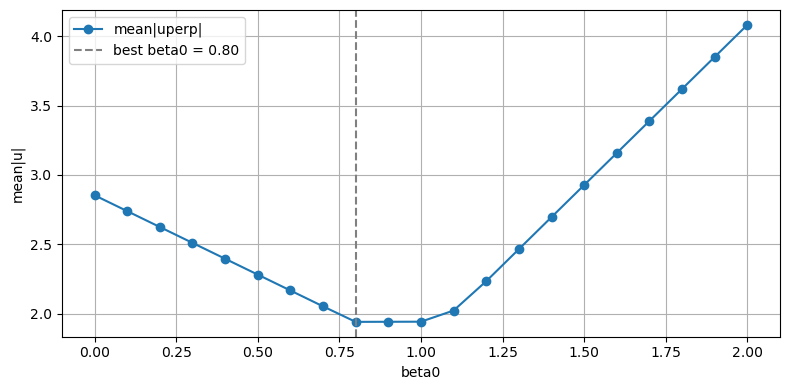

In [290]:
beta0s      = list(results.keys())
score_uperp = [results[b][0] for b in beta0s]
score_upara = [results[b][1] for b in beta0s]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(beta0s, score_uperp, marker="o", label="mean|uperp|")
#ax.plot(beta0s, score_upara, marker="o", label="mean|upara|")
ax.axvline(best_beta0, color="gray", linestyle="--", label=f"best beta0 = {best_beta0:.2f}")
ax.set_xlabel("beta0")
ax.set_ylabel("mean|u|")
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

#fig.savefig(f"{plot_dir/beta0_determination_tbird.pdf")

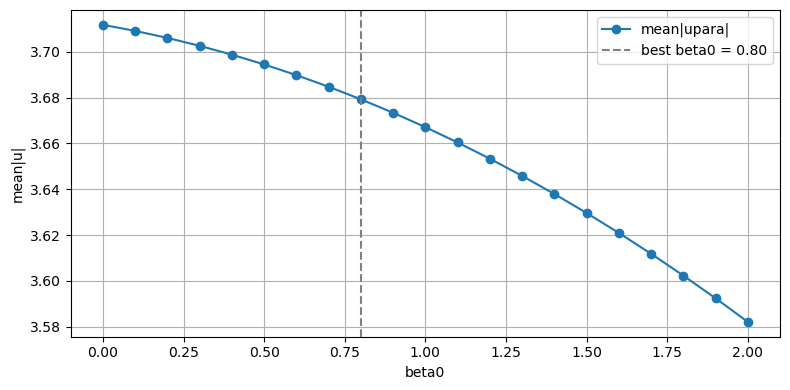

In [291]:
beta0s      = list(results.keys())
score_uperp = [results[b][0] for b in beta0s]
score_upara = [results[b][1] for b in beta0s]

fig, ax = plt.subplots(figsize=(8, 4))
#ax.plot(beta0s, score_uperp, marker="o", label="mean|uperp|")
ax.plot(beta0s, score_upara, marker="o", label="mean|upara|")
ax.axvline(best_beta0, color="gray", linestyle="--", label=f"best beta0 = {best_beta0:.2f}")
ax.set_xlabel("beta0")
ax.set_ylabel("mean|u|")
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

# Check for time offsets

instruments where the time is manually adjusted might have time offsets. These can be noted in the config file.

In [15]:
def check_time_shift(p1, p2, max_lag_seconds=60, plot=True):
    """
    p1, p2: xarray DataArrays with a 'time' dimension
    Detects time shift between two pressure signals via cross-correlation.
    """
    
    # 1. Interpolate p2 onto p1's time axis (common grid required)
    p2_interp = p2.interp(time=p1.time, method="linear")

    # 2. Remove slow trends — only fluctuations carry timing info
    #    (high-pass: subtract a rolling mean)
    window = 600  # samples; tune to your sampling rate
    p1_anom = p1 - p1.rolling(time=window, center=True, min_periods=1).mean()
    p2_anom = p2_interp - p2_interp.rolling(time=window, center=True, min_periods=1).mean()

    # 3. Drop NaNs (must be same length)
    a = p1_anom.values
    b = p2_anom.values
    mask = np.isfinite(a) & np.isfinite(b)
    a, b = a[mask], b[mask]

    # 4. Normalize
    a = (a - a.mean()) / a.std()
    b = (b - b.mean()) / b.std()

    # 5. Cross-correlation
    corr = signal.correlate(a, b, mode="full")
    lags = signal.correlation_lags(len(a), len(b), mode="full")

    # Convert lags from samples to seconds
    dt = float(p1.time.diff("time").median()) / 1e9  # ns → seconds
    lags_sec = lags * dt

    # Restrict to max_lag window
    mask_lag = np.abs(lags_sec) <= max_lag_seconds
    corr_windowed = corr[mask_lag]
    lags_windowed = lags_sec[mask_lag]

        # Envelope of the cross-correlation
#    envelope = np.abs(hilbert(corr_windowed))
#    best_lag = lags_windowed[np.argmax(envelope)]
    #print(f"Lag from envelope: {best_lag:.2f} s")
    best_lag = lags_windowed[np.argmax(corr_windowed)]
    print(f"Estimated time shift: {best_lag:.2f} s  (postive → p1 leads p2, i.e. p2 needs to be shifted by {best_lag * 1000:.0f} ms)")

    if plot:
        fig, axes = plt.subplots(2, 1, figsize=(10, 6))

        axes[0].plot(p1.time, p1_anom, label="proc.p_air", alpha=0.7)
        axes[0].plot(p2_interp.time, p2_anom, label="out_ds.p_air", alpha=0.7)
        axes[0].set_ylabel("pressure anomaly")
        axes[0].legend()
        axes[0].set_title("Detrended pressure fluctuations")

        axes[1].plot(lags_windowed, corr_windowed)
        axes[1].axvline(best_lag, color="red", linestyle="--",
                        label=f"peak lag = {best_lag:.2f} s")
        axes[1].set_xlabel("lag (s)")
        axes[1].set_ylabel("cross-correlation")
        axes[1].set_title("Cross-correlation (restricted to ±{max_lag_seconds} s)")
        axes[1].legend()

        plt.tight_layout()
        plt.show()

    return best_lag

In [211]:
flight = 10
pf = "partector"
if pf == "partector_tbird":
    dev = "partector_dms_tbird"
else:
    dev = pf
config_file = "/Users/lakoeh001/AWI/Programmierung/sanat_processing/config_sanat.yaml"

In [212]:
config = h.import_dictionary(config_file)
outdir_totest = config["paths"]["outdirs"][pf]
flight_date = str(config["flights"][flight]["date"]).replace("-","")
campaign = config["campaign"]["name"]
if pf[-5:] == "tbird":
    outdir_nb = config["paths"]["outdirs"]["tbird"]
    fn_ref = outdir_nb+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_tbird_100Hz.nc"
else:
    outdir_nb = config["paths"]["outdirs"]["noseboom"]
    fn_ref = outdir_nb+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_noseboom_100Hz.nc"
fn = outdir_totest+"/"+campaign+"_"+flight_date+f"_RF{flight:02}_{pf}.nc"

ref = xr.open_dataset(fn_ref)
totest = xr.open_dataset(fn)

Estimated time shift: 0.00 s  (postive → p1 leads p2, i.e. p2 needs to be shifted by 0 ms)


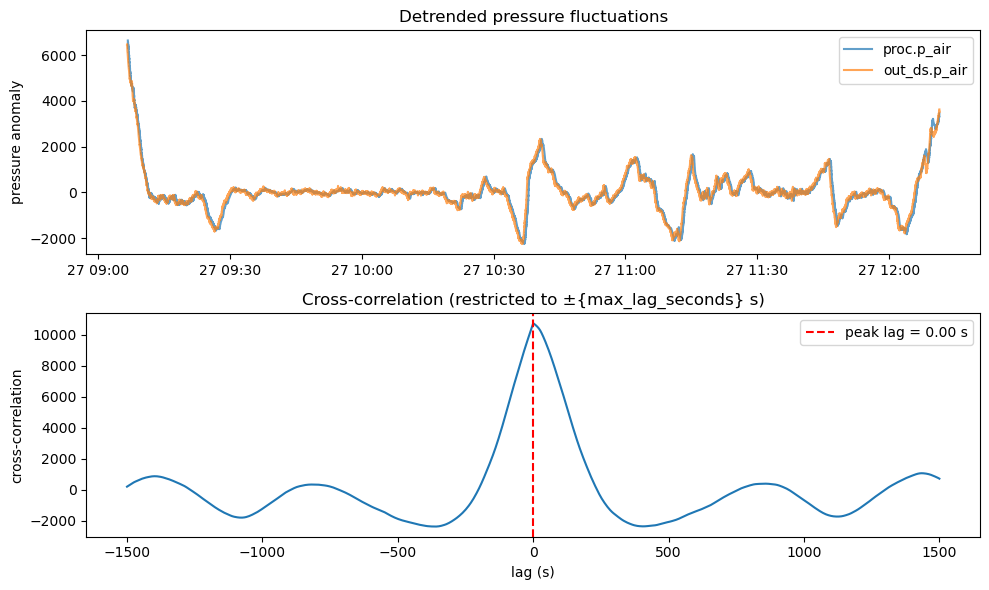

In [203]:
lag = check_time_shift(totest.sel(time = slice(None,None)).p_amb.sel(time = slice(None,None)), ref.p_air, max_lag_seconds=1500)

# Plot devices

## Partector

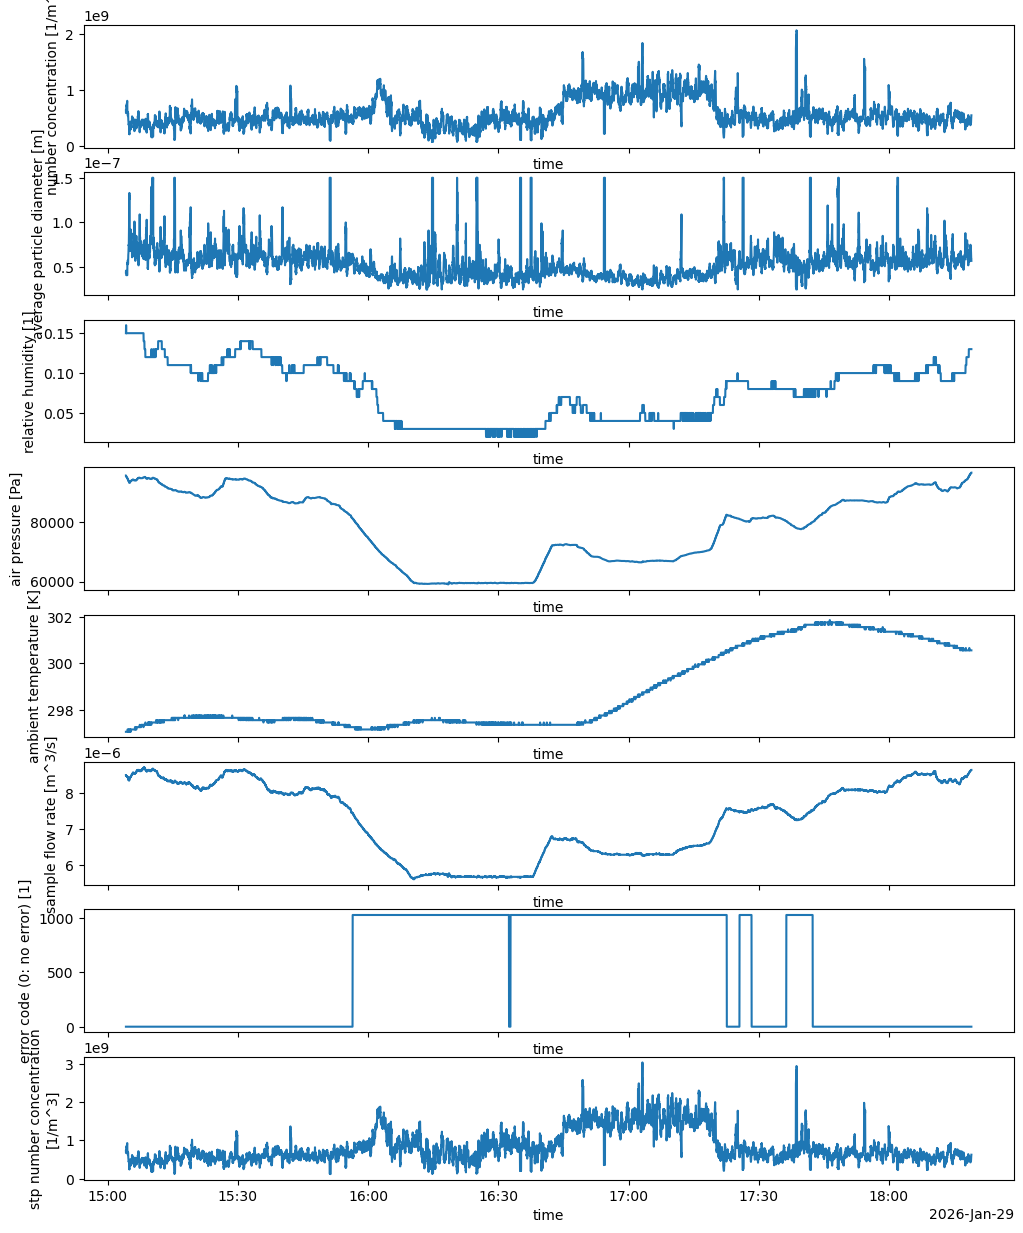

In [213]:
# Partector
fig, axs = plt.subplots(8,1,figsize=(12,15),sharex=True)

for v, ax in zip(list(totest.keys()), fig.get_axes()):
    totest[v].plot(ax = ax)

## MCPC

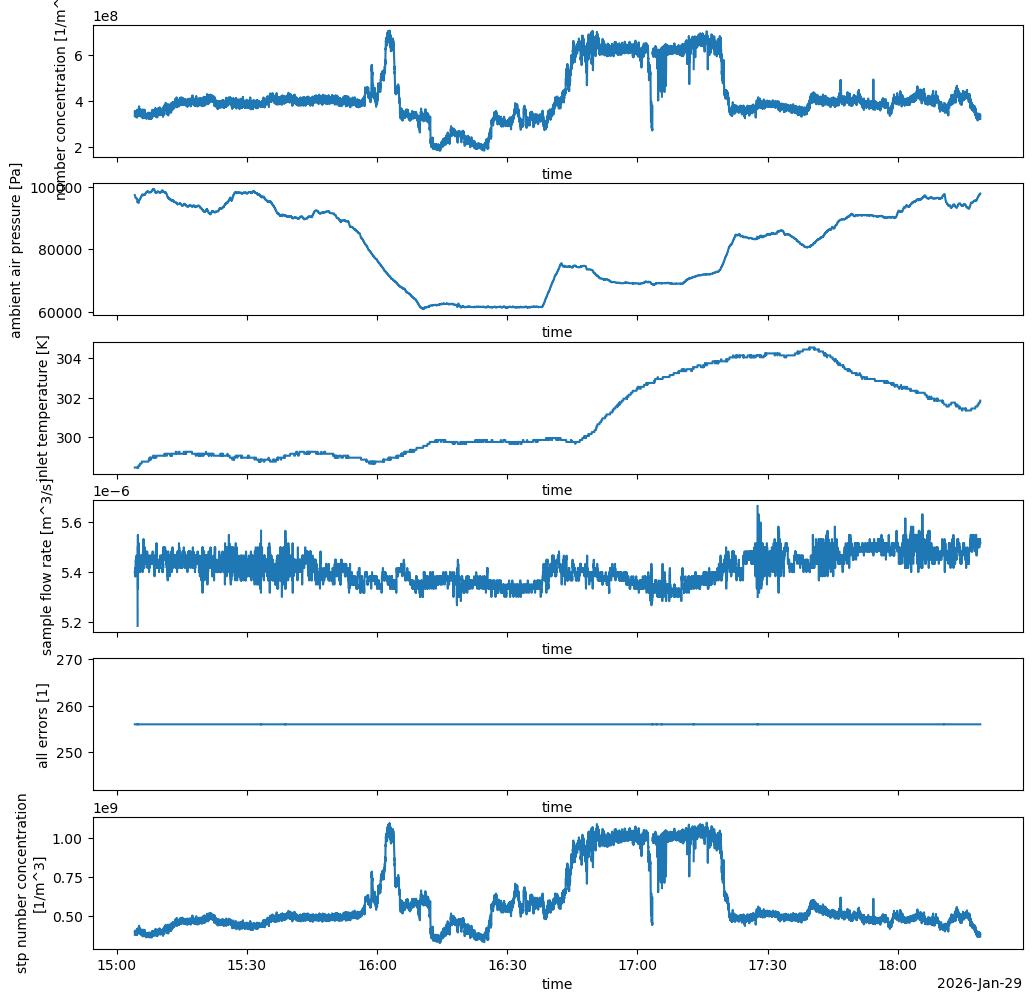

In [85]:
#MCPC
fig, axs = plt.subplots(6,1,figsize=(12,12),sharex=True)

for v, ax in zip(list(totest.keys()), fig.get_axes()):
    totest[v].plot(ax = ax)

## KT19

In [28]:
ds = xr.open_dataset("/Users/lakoeh001/AWI/Campaigns/20240403BACSAMII/Daten/Prozessierung/kt19/BACSAM2_20240429_RF11_kt19.nc")

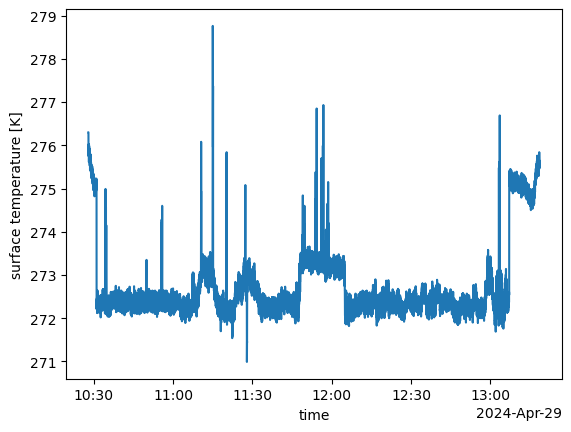

In [5]:
ds.t_surface.plot()

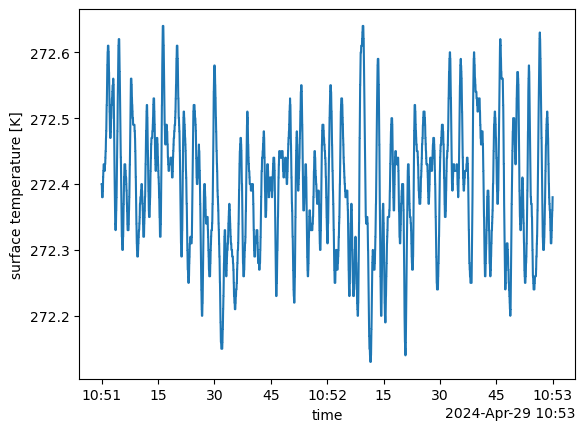

In [6]:
ds.groupby("segment")[5].t_surface.plot()

In [37]:
ds.time.diff("time").mean()

<xarray.DataArray 'time' ()>
array(19997713, dtype='timedelta64[ns]')

In [38]:
19997713/10**9

0.019997713

In [39]:
1/0.019997713

50.005718153870895

In [40]:
ds

<xarray.Dataset>
Dimensions:    (time: 511559)
Coordinates:
  * time       (time) datetime64[ns] 2024-04-29T10:28:00.005751 ... 2024-04-2...
    segment    (time) int64 ...
    lat        (time) float64 ...
    lon        (time) float64 ...
    alt        (time) float64 ...
Data variables:
    t_surface  (time) float64 ...
Attributes: (12/13)
    title:        BACSAM 2 campaign with Polar 6: KT19 of RF11 (2024-04-29)
    author:       Laura Köhler, Zsofia Juranyi
    institution:  Alfred-Wegener-Institut
    contact:      laura.koehler@awi.de
    date:         2026-07-01
    serial:       3071
    ...           ...
    doi:          tba
    conventions:  CF-1.7
    processing:   processed with polair (https://github.com/LauraKoehler/pola...
    comment:      part of <doi>
    campaign:     BACSAM2
    platform:     Polar 6

## radiation

In [48]:
ds = xr.open_dataset("/Users/lakoeh001/AWI/Campaigns/20240403BACSAMII/Daten/Prozessierung/radiation/BACSAM2_20240425_RF09_radiation.nc")

In [26]:
sigma = 5.670374 * 10**(-8)
blackbody = None
for v in ["lw_up", "lw_down", "sw_up", "sw_down"]:
    blackbodyrad = (sigma * ds[f"t_{v}"]**4)
    try:
        blackbody[f"{v}_bb"] = blackbodyrad
    except:
        blackbody = blackbodyrad.to_dataset(name = f"{v}_bb")

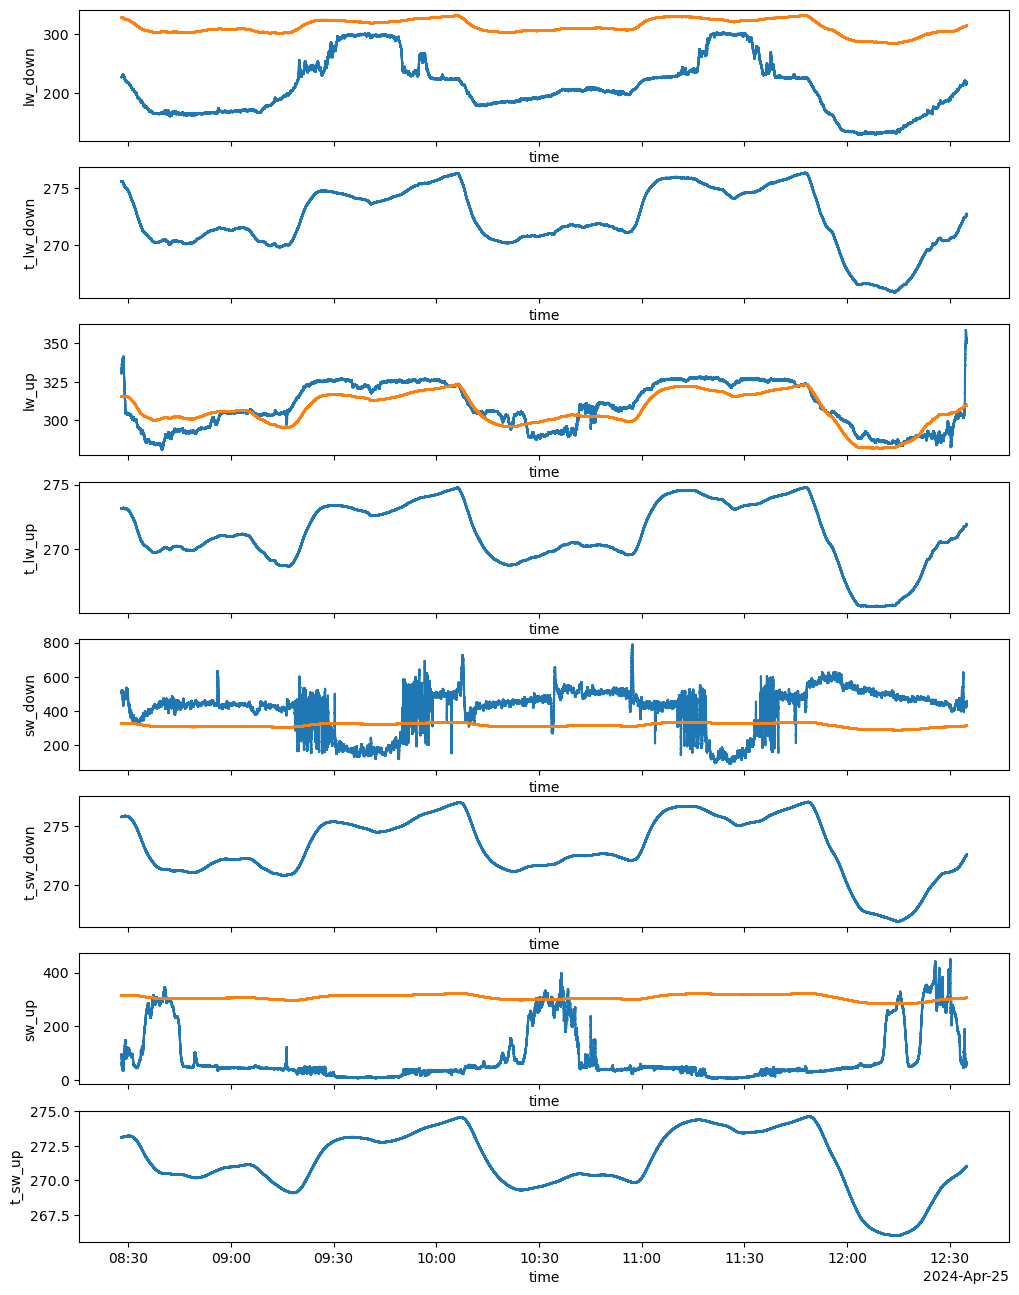

In [27]:
#MCPC
fig, axs = plt.subplots(8,1,figsize=(12,16),sharex=True)

for v, ax in zip(list(ds.keys()), fig.get_axes()):
    ds[v].plot(ax = ax)
    if not v[0] == "t":
        blackbody[f"{v}_bb"].plot(ax = ax)
    ax.set_ylabel(v)

In [51]:
ds.time.diff("time").mean()

<xarray.DataArray 'time' ()>
array(47619167, dtype='timedelta64[ns]')

In [53]:
1/0.047619167

20.999947353131986

In [54]:
ds

<xarray.Dataset>
Dimensions:    (time: 311219)
Coordinates:
  * time       (time) datetime64[ns] 2024-04-25T08:28:00.017090 ... 2024-04-2...
    segment    (time) int64 ...
    lat        (time) float64 ...
    lon        (time) float64 ...
    alt        (time) float64 ...
Data variables:
    lw_down    (time) float64 ...
    t_lw_down  (time) float64 ...
    lw_up      (time) float64 ...
    t_lw_up    (time) float64 ...
    sw_down    (time) float64 ...
    t_sw_down  (time) float64 ...
    sw_up      (time) float64 ...
    t_sw_up    (time) float64 ...
    pitch      (time) float64 ...
    roll       (time) float64 ...
Attributes: (12/13)
    title:        BACSAM 2 campaign with Polar 6: irradiance of RF09 (2024-04...
    author:       Laura Köhler, Zsofia Juranyi
    institution:  Alfred-Wegener-Institut
    contact:      laura.koehler@awi.de
    date:         2026-07-01
    instruments:  pyrgeometer & pyranometer top/bottom
    ...           ...
    doi:          tba
    conventions:  CF-1.7
    processing:   processed with polair (https://github.com/LauraKoehler/pola...
    comment:      part of <doi>
    campaign:     BACSAM2
    platform:     Polar 6

## UHSAS

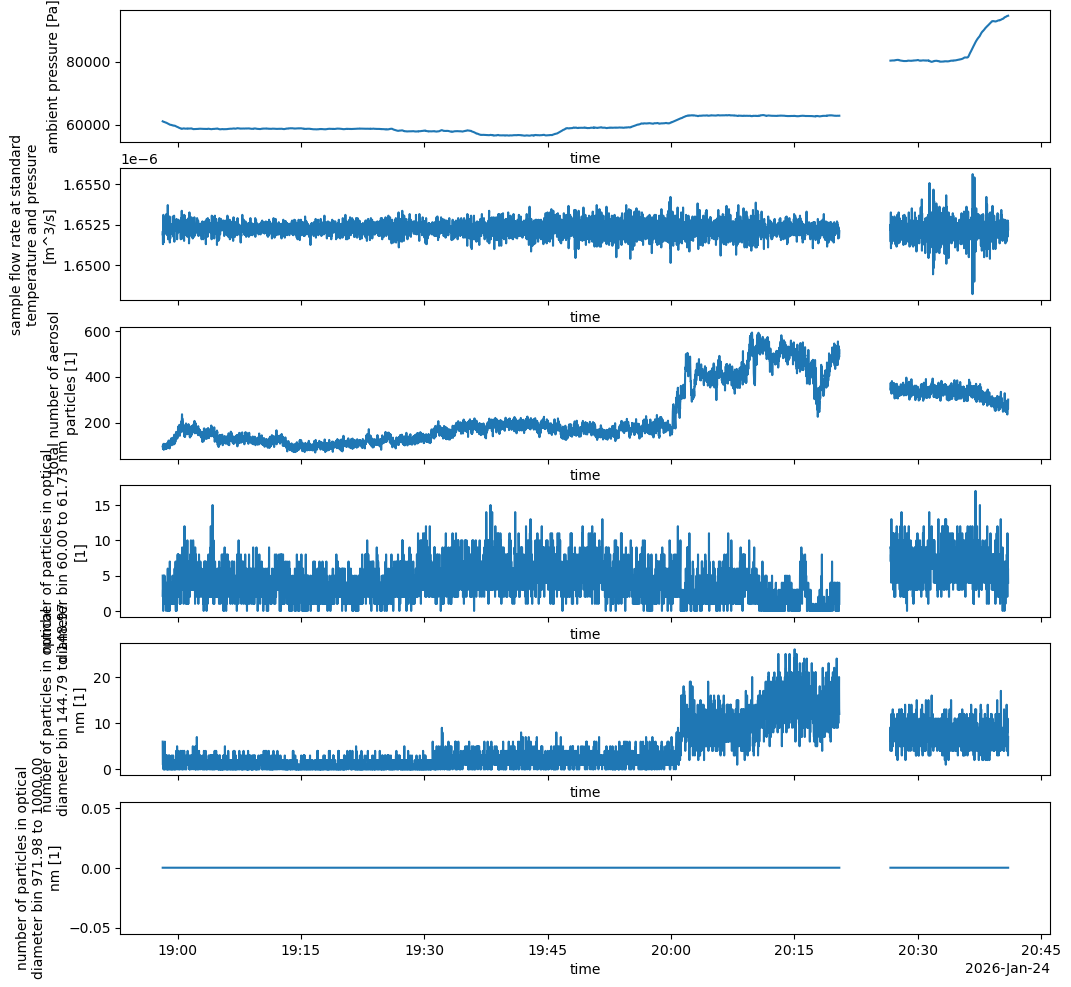

In [66]:
#UHSAS
fig, axs = plt.subplots(6,1,figsize=(12,12),sharex=True)

for v, ax in zip(['p_amb', 'flow_rate', 'total_counts', 'counts_60_62nm', 'counts_145_149nm','counts_972_1000nm'], fig.get_axes()):
    totest[v].plot(ax = ax)

### Timestamp correction for RF09

The timestamps of RF09 were corrupted. The time offsets are:
* 20260129084309.xls: -14000 ms, note that there are a few timestamps at the end which are also shifted quite a bit and not included in the final file
* 20260129094426.xls: 1741480 ms

This was corrected by hand by replacing the time column with the corrected timestamps and deleting the overlapping ones from the first file at the end. The new files are denoted by the ending _corr. All used scripts are stored in this subchapter.

In [322]:
def read_uhsas(path, name_row=0, encoding="latin-1", date_format="%m/%d/%Y"):
    """
    Returns a DataFrame indexed by timestamp (from the date + time columns).
    The ms-since-midnight column is kept as 'ms_since_midnight' for checking.

    name_row : which of the two header lines holds the column names (0 or 1).
               The other line is stored in df.attrs["header_other"].
    date_format : strptime format of the date column ("%m/%d/%Y" -> 1/21/2026).
    """
   # --- header lines ---------------------------------------------------
    with open(path, "r", encoding=encoding, errors="replace") as f:
        headers = [next(f).rstrip("\r\n").split("\t") for _ in range(2)]
    names = [h.strip() for h in headers[name_row]]
    other = [h.strip() for h in headers[1 - name_row]]

    # --- data: read everything as text first ----------------------------
    n_cols = len(names) + 2
    raw = pd.read_csv(
        path, sep="\t", header=None, skiprows=2, names=range(n_cols),
        encoding=encoding, engine="python", dtype=str,
    )
    raw = raw.dropna(how="all")

    # --- unique column names --------------------------------------------
    names = names + ["Total_counts", "seconds_since_midnight"]
    seen, unique = {}, []
    for n in names:
        n = n or "unnamed"
        if n in seen:
            seen[n] += 1
            n = f"{n}_{seen[n]}"
        else:
            seen[n] = 0
        unique.append(n)
    raw.columns = unique

    # --- timestamp from first two columns -------------------------------
    # Time looks like '12:00:35.83  PM' (AM/PM, sometimes double spaces)
    squeeze = lambda s: s.str.replace(r"\s+", " ", regex=True).str.strip()
    date_s = squeeze(raw.iloc[:, 0])
    time_s = squeeze(raw.iloc[:, 1]).str.upper()
    timestamp = pd.to_datetime(
        date_s + " " + time_s,
        format=date_format + " %I:%M:%S.%f %p",
        errors="coerce",
    )

    # --- numeric data: everything except date/time ----------------------
    df = raw.iloc[:, 2:].apply(pd.to_numeric, errors="coerce")
    df.index = pd.DatetimeIndex(timestamp, name="time")

    # drop rows where the timestamp couldn't be parsed
    bad = df.index.isna().sum()
    if bad:
        print(f"Warning: {bad} rows with unparsable date/time were dropped")
        df = df[~df.index.isna()]

    # --- last column: seconds since midnight (auto-detect s vs ms) ------
    clk = df["seconds_since_midnight"].to_numpy(dtype=float)
    if np.nanmedian(clk) > 86400 * 1.5:       # far too big for seconds -> ms
        print("Last column looks like milliseconds; converting to seconds")
        clk = clk / 1000.0
        df["seconds_since_midnight"] = clk

    # --- consistency check: time string vs clock column -----------------
    tod_s = np.asarray((df.index - df.index.normalize()).total_seconds())
    diff_ms = np.abs(tod_s - clk) * 1000
    print(f"Max |time column - clock column| = {np.nanmax(diff_ms):.0f} ms "
          f"(median {np.nanmedian(diff_ms):.0f} ms)")

    # --- time as a normal first column, row number as index -------------
#    df = df.reset_index()          # 'time' becomes column 0, index = 0..n-1
#    df.index.name = "row"

    df.attrs["header_other"] = dict(zip(unique[2:-2], other[2:]))
    df.attrs["source"] = path
    return df

Max |time column - clock column| = nan ms (median nan ms)


/var/folders/j4/fclf6j0x39j3cnr71ql3kg0r4jskdr/T/ipykernel_17470/643368066.py:60: RuntimeWarning: All-NaN slice encountered
  if np.nanmedian(clk) > 86400 * 1.5:       # far too big for seconds -> ms
/var/folders/j4/fclf6j0x39j3cnr71ql3kg0r4jskdr/T/ipykernel_17470/643368066.py:68: RuntimeWarning: All-NaN slice encountered
  print(f"Max |time column - clock column| = {np.nanmax(diff_ms):.0f} ms "
/var/folders/j4/fclf6j0x39j3cnr71ql3kg0r4jskdr/T/ipykernel_17470/643368066.py:69: RuntimeWarning: All-NaN slice encountered
  f"(median {np.nanmedian(diff_ms):.0f} ms)")


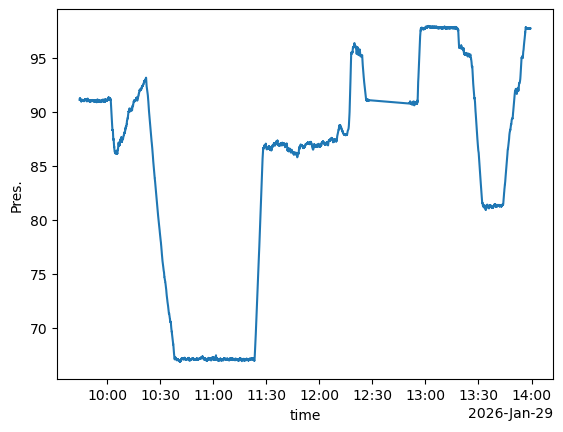

In [360]:
fn = "/Users/lakoeh001/AWI/Campaigns/20260103SANAT/Daten/RF09_20260129/UHSAS/corrupted_timestamps/20260129094426.xls"
df = read_uhsas(fn)
ds = df.to_xarray()
ds["Pres."].plot()

In [315]:
import pandas as pd

def format_uhsas_time(t):
    t = pd.Series(pd.DatetimeIndex(t))
    hh = t.dt.strftime("%I")
    mm = t.dt.strftime("%M")
    ss = t.dt.strftime("%S")
    frac = (t.dt.microsecond // 10000).map(lambda x: f"{x:02d}")  # 2-decimal centiseconds
    ampm = t.dt.strftime("%p")
    return hh + ":" + mm + ":" + ss + "." + frac + "  " + ampm    # double space before AM/PM

def export_time_column(ds, path, time_dim="time", header="Time"):
    times_fmt = format_uhsas_time(ds[time_dim].values)
    with open(path, "w", newline="\r\n") as f:
        f.write(header + "\n")
        f.write("\n".join(times_fmt) + "\n")

In [342]:
corr = ds

In [343]:
corr["time"] = ds.time - np.timedelta64(1741480,"ms")

In [345]:
export_time_column(corr, "/Users/lakoeh001/AWI/Campaigns/20260103SANAT/Daten/RF09_20260129/time_corrs_02.xls")

## LICOR

In [1091]:
ds = xr.open_dataset("/Users/lakoeh001/AWI/Campaigns/20260103SANAT/Daten/Prozessierung/licor/SANAT_20260125_RF04_licor.nc")
#ds = xr.open_dataset("/Users/lakoeh001/AWI/Campaigns/20260103SANAT/Daten/Prozessierung/licor_tbird/SANAT_20260126_RF06_licor_tbird.nc")

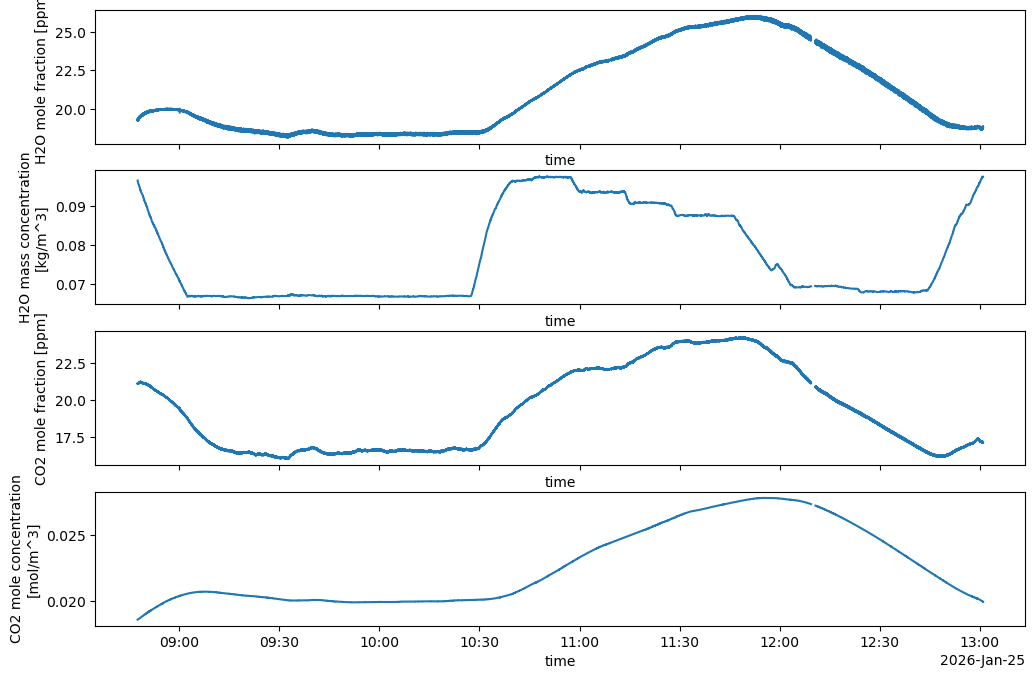

In [1092]:
#LI-COR
fig, axs = plt.subplots(4,1,figsize=(12,8),sharex=True)

for v, ax in zip(list(ds.keys()), fig.get_axes()):
    ds[v].plot(ax = ax)

## Dropsondes

In [5]:
ds = xr.open_dataset("/Users/lakoeh001/AWI/Campaigns/20260103SANAT/Daten/Prozessierung/dropsondes/SANAT_dropsondes.nc")

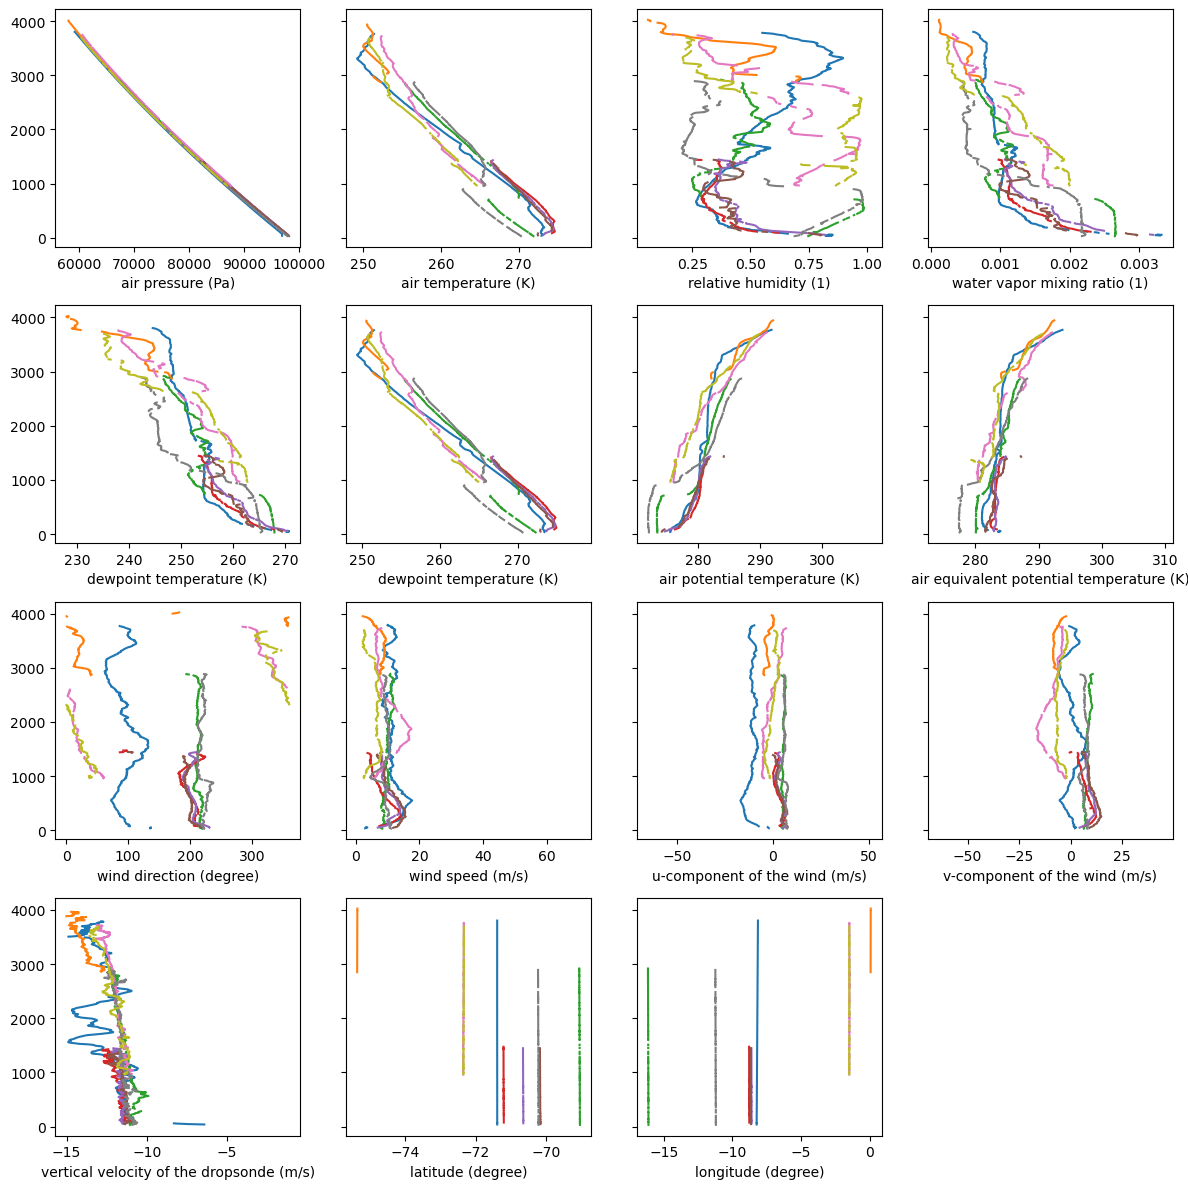

In [1080]:
fig, axs = plt.subplots(4,4,figsize=(12,12),sharey=True)
axs = axs.flatten()

variables = ["p_air", "t_air", "rh", "mr", "dp", "tv", "theta", "theta_e", "wdir", "wspd", "u_air", "v_air", "w_sonde", "lat", "lon"]

for n in ds.number.values:
    toplot = ds.sel(number = n)
    for v, ax in zip(variables, axs):
            ax.plot(toplot[v], toplot["alt"])
            ax.set_xlabel(f"{toplot[v].long_name} ({toplot[v].units})")

for ax in axs[len(variables):]:
    ax.set_visible(False)

plt.tight_layout()

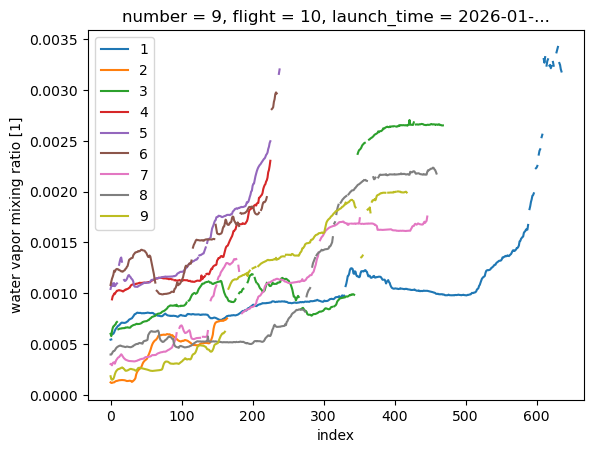

In [1077]:
v = "mr"
for n in ds.number.values:
    ds.sel(number = n)[v].plot(label = n)

plt.legend()